# Where Llama goes when an algorithm is banned — demo

**Artifact** `art_Q-qh-9HhPoWo` (experiment 15) · **Model** Llama-3.1-8B-Instruct, bf16, revision `0e9e39f` · **Script** `method.py`

**Question.** Can a prompt make an LLM produce a *different* solution than its default? If a coding prompt says *"Do not use X"*, does the model simply **subtract** X and fall to whatever it would have written next (its *next rung*), or does naming X **substitute** a specific associate of X?

**Claim 1** says the ban removes the default algorithm **D** and sends the model to a *predictable* next rung. The artifact tests this on a frozen 12-task coding bench (k-th smallest, substring search, two-sum, connected components, ...). Four **ban-free** forecast families predict where the model lands:

| family | how the forecast is built, without ever showing the model the ban |
|---|---|
| **SUBTRACT** | Exact signature-n-gram vetoes during decoding (truncate-and-redraw in vLLM): remove X's surface tokens and see where generation goes. |
| **LADDER** | Generic pushes: a nonce ban (*"Do not use the Zorblax method"*), a novelty instruction, and 3 matched-norm random directions added to the residual stream at layers 11–21. |
| **ASSOCIATE** | Llama's own answer to *"What is the standard alternative to X for this task?"*, in mass-transfer form. |
| **PROXIMITY** | The survivor whose programs are nearest to X's in Zhang-Shasha AST edit distance, in mass-transfer form. |

All forecasts were hash-chained **before** any ban prompt was rendered. Then 1,800 bans were sampled (18 events × 5 templates × 20 samples) and scored by the **frozen C1 rule**: smoothed log score, an avoidance gate, wins by ≥ 0.10 nats, ≥ 3 wins to advance, then Wilcoxon + Holm and a top-1 binomial test.

**Reported result (within Llama, before pooling): NO FAMILY ADVANCES (aimed, unresolved).** SUBTRACT and LADDER beat PROXIMITY (Holm-rejected), none separates from ASSOCIATE, and LADDER and ASSOCIATE hit the realised landing above chance (7/13 each).

### What this notebook runs

`method.py` is a 13-stage pipeline (one sub-command per stage). The GPU stages `gen1`, `hf`, `push`, `veto`, `ban` and `screen` (vLLM on an NVIDIA L4, about 1.8 GPU-hours) and the OpenRouter judge in `label` cannot run in a 10-minute CPU session. The notebook therefore starts from their **frozen outputs**: the label of every Llama generation, packed in `mini_demo_data.json`. It re-runs the CPU half of `method.py` with the original code, stage by stage, and checks each stage against the numbers the artifact committed or reported:

1. `freeze`: decision set (FFH homogeneity test), frozen default **D**, present-minor events (C4/C5).
2. `assoc`: forced-program adherence (C7) and Llama's own association map (C6).
3. `commit`: `_forecast_ctx` + `build_event`, the four ban-free forecasts of every event (F).
4. `proximity`: a Zhang-Shasha re-run for one event.
5. `analyse`: the frozen C1 scoring rule, sensitivities and descriptive layers (H).

*(The artifact's path-task screen ("implement path search", where Llama's default is BFS) uses the same machinery but is descriptive and is not part of this demo.)*

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (logging), zss (Zhang-Shasha tree edit distance), rapidfuzz (token Levenshtein) — NOT on Colab, always install
_pip('loguru==0.7.3', 'zss==1.2.0', 'rapidfuzz==3.14.1')

# numpy, scipy, pandas, matplotlib — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import argparse
import sys
import time
from pathlib import Path

from loguru import logger  # noqa: E402

# method.py also ran:
#   sys.path.insert(0, str(Path(__file__).resolve().parent))
#   from src.ws import DATA as DATA_DIR, RESULTS, set_ram_limit, setup_logging, write_json
# The src/ package and the frozen bench (inputs/exp11) do not ship with this notebook. The functions each stage needs
# are copied into the cells below; file reads become lookups in the loaded `data`, file writes become return values.

# imports of the copied src/ modules (ws, stats_util, freeze, scoring, forecasts, proximity, analysis, label, canon)
import ast
import builtins
import collections
import datetime as dt
import hashlib
import io
import json
import keyword
import math
import multiprocessing as mp
import random
import re
import statistics
import tokenize
from collections import Counter, defaultdict
from types import SimpleNamespace
from typing import Any, Iterable

import numpy as np

# notebook only: tables and figures
import pandas as pd
import matplotlib.pyplot as plt

# src/ws.setup_logging, minus the log file
logger.remove()
log_sink_id = logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-3/experiment-15/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
if "tasks" not in data.get("metadata", {}):   # the URL can still serve an older demo file with another layout
    print("The GitHub copy has a different layout; using the local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
EXAMPLES = data["datasets"][0]["examples"]   # dataset `llama_bench_events`: the 18 frozen ban events
TASKS_DATA = data["metadata"]["tasks"]       # the 12 frozen tasks: algorithm catalogue + task-level label rows
print(data["metadata"]["title"], "|", data["metadata"]["model"])
print(f"{len(EXAMPLES)} ban events, {len(TASKS_DATA)} tasks; label rows per phase: {data['metadata']['row_counts']}")

The GitHub copy has a different layout; using the local mini_demo_data.json
Where Llama goes when an algorithm is banned (mini demo data) | meta-llama/Llama-3.1-8B-Instruct@0e9e39f (bf16)
18 ban events, 12 tasks; label rows per phase: {'pilot': 600, 'B1': 600, 'B4': 600, 'B3r1': 1000, 'B5': 1200, 'B3r2': 540, 'E3': 1800, 'D2': 2250, 'D3': 1338, 'G1': 1200, 'G2': 600}


## Configuration

Every tunable parameter lives in the next cell. The C1 constants (smoothing 0.93 f + 0.05 U(S) + 0.02 δ(other), gate at avoidance ≥ 0.5 with ≥ 20 non-banned attempts, 0.10-nat win margin, 3 wins to advance) are part of the hash-chained rule. They are **not** tunables and stay in the scoring cell.

Phase codes used in the data: `pilot` = exp11's FP8 pilot; `B1` = bf16 neutral-twin baseline; `B4` = veto pass-1; `B3r1`/`B3r2` = forced programs; `B5` = nonce ban + novelty prompt; `E3` = random-direction pushes; `D2`/`D3` = signature vetoes (one-shot / persistent); `G1`/`G2` = the real bans (modal / present-minor events).

In [5]:
# ---------------------------------------------------------------------------------------------------------------
# Tunable parameters. Original artifact values in [brackets].
# ---------------------------------------------------------------------------------------------------------------
N_EVENTS = 18         # frozen ban events scored in Step H                                          [all 18]
FFH_DRAWS = 100_000   # Monte Carlo draws of the Fisher-Freeman-Halton homogeneity test (freeze)    [100_000]
N_BOOT = 2_000        # task-cluster bootstrap resamples of mean log-score differences (C1)         [2_000]
N_NULL_C2B = 1_000    # template-bootstrap JSD null draws (C2b, descriptive)                        [1_000]
RAREFY_REPS = 2_000   # resamples of the rarefied Hill-1 diversity in the event table               [2_000]
PROX_K = 6            # Zhang-Shasha programs per side (k x k pairs per survivor)                   [10, cut to 6 by the ETA rule]
PROX_K_TOK = 30       # canonical-token Levenshtein sensitivity: programs per side                  [30]

# method.py's command-line arguments (argparse in main()); one Namespace serves every stage called below
args = argparse.Namespace(phases="", workers=1, limit=0, no_judge=True)

## Frozen constants and the bench catalogue (`src/ws.py`, `src/prompts_llama.py`, `bench/common/order.py`, `src/label.py`)

The pieces of the workspace module that the CPU stages read are below. The bench catalogue (algorithm *modes* per task, display names, aliases) comes from `data`, standing in for `inputs/exp11/bench/<task>/spec.json`. `mentions` decides whether a program still *names* an algorithm; the event table uses it for the **disguise rate**, the share of banned-but-used programs that never name X. `extract` pulls the `solve` code block out of a generation.

In [6]:
# ---- src/ws.py: frozen constants (paths dropped; everything is read from `data`) ----
MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"
MODEL_REV = "0e9e39f249a16976918f6564b8830bc894c89659"
MODEL_TAG = "meta-llama/Llama-3.1-8B-Instruct@0e9e39f(bf16)"
EOS_IDS = [128001, 128008, 128009]
MAX_TOKENS = 1024
FROZEN_TASKS = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]
PUSH_LAYERS = list(range(11, 22))       # decoder layers 11..21 (hidden_states[l+1] in HF)
RANDDIR_SEEDS = [20261020, 20261021, 20261022]
TEMPLATES = {
    1: "Do not use {X} for this task.",
    2: "Your solution must not rely on {X}.",
    3: "Avoid {X} entirely.",
    4: "{X} is not allowed here.",
    5: "Write a correct solution that does not use {X}.",
}
NONCE_X = "the Zorblax method"
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
SMOOTH = {"f": 0.93, "uniform_S": 0.05, "other": 0.02}


# src/commit.py
def utc_now() -> str:
    return dt.datetime.now(dt.timezone.utc).isoformat(timespec="microseconds")


# ---- stand-in for src/prompts_llama.modes / .display (the bench's spec.json catalogue, carried in `data`) ----
P = SimpleNamespace(modes=lambda task: TASKS_DATA[task]["modes"],
                    display=lambda task, mode: TASKS_DATA[task]["display"][mode])

# ---- bench/common/order.py (catalogue aliases carried in `data`) ----
TASKS = {t: {"aliases": v["aliases"], "modes": v["modes"]} for t, v in TASKS_DATA.items()}
display_name = P.display


def _phrases(task: str, mode: str) -> set[str]:
    ph = {a.lower() for a in TASKS[task]["aliases"][mode]}
    d = re.sub(r"^(a|an|the)\s+", "", display_name(task, mode).lower())
    ph.add(re.sub(r"\s*\(.*?\)", "", d).strip())
    return {p for p in ph if len(p) >= 2}


def mentions(task: str, text: str) -> dict[str, int]:
    low = text.lower()
    pos = {}
    for m in TASKS[task]["modes"]:
        for p in _phrases(task, m):
            for mm in re.finditer(r"(?<![a-z0-9])" + re.escape(p) + r"(?![a-z0-9])", low):
                pos[m] = min(pos.get(m, 10**9), mm.start())
    return pos


# ---- src/label.py: the code block a generation is scored on ----
FENCE_ALL = re.compile(r"```[ \t]*([A-Za-z0-9_+-]*)[ \t]*\n(.*?)```", re.S)
OPEN_FENCE = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n(.*)$", re.S)
DEF_SOLVE = re.compile(r"^\s*def\s+solve\s*\(", re.M)


def extract(text: str | None) -> tuple[str | None, dict[str, Any]]:
    info = {"n_blocks": 0, "rule": None, "prose_before": None, "prose_after": None}
    if not text:
        return None, info
    blocks = [(m.group(1).lower(), m.group(2), m.start(), m.end()) for m in FENCE_ALL.finditer(text)]
    info["n_blocks"] = len(blocks)
    chosen = None
    for lang, body, a, b in blocks:
        if lang in ("python", "python3", "py") and DEF_SOLVE.search(body):
            chosen, info["rule"] = (body, a, b), "first_python_with_solve"
            break
    if chosen is None:
        cands = [(len(body), body, a, b) for lang, body, a, b in blocks if DEF_SOLVE.search(body)]
        if cands:
            _, body, a, b = max(cands, key=lambda x: x[0])
            chosen, info["rule"] = (body, a, b), "largest_with_solve"
    if chosen is None:
        last_close = blocks[-1][3] if blocks else 0
        m = OPEN_FENCE.search(text, last_close)
        if m and DEF_SOLVE.search(m.group(1)):
            chosen, info["rule"] = (m.group(1), m.start(), len(text)), "open_block"
    if chosen is None:
        return None, info
    body, a, b = chosen
    info["prose_before"] = len(text[:a].strip())
    info["prose_after"] = len(text[b:].strip())
    return body, info


L = SimpleNamespace(extract=extract)


# what the model was asked: the W1 ban prompt of the first event (user turn; rendered with the Llama-3.1 chat template)
print(EXAMPLES[0]["input"][:1200])

Event T03|modal|full_sort (modal): Llama-3.1-8B-Instruct is told not to use a full sort on task T03; default D = full_sort. Survivors: size_k_heap, heapify_pop, quickselect, median_of_medians, counting_sort. W1 ban prompt:
Do not use a full sort for this task.

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.


## Rebuild the two row tables the stages read

The original stages read `data/labels.jsonl`, with one label row per generation (task, phase, condition, label, passed, scrub check), and `data/raw_gen.jsonl`, with one raw row per generation (event id, ban template, veto arm / round / weight / hit, text). `mini_demo_data.json` stores the same rows grouped by task and by event. The cell below flattens them back into those two tables, so that the original functions run on them unchanged.

In [7]:
labels: list[dict[str, Any]] = []
raw_by: dict[str, dict[str, Any]] = {}
for t, rec in TASKS_DATA.items():
    for r in rec["decision_rows"] + rec["push_rows"] + rec["forced_rows"]:   # pilot/B1/B4, B5/E3, B3r1/B3r2
        labels.append(dict(r, task=t))
        raw_by[r["row_id"]] = {"row_id": r["row_id"], "phase": r["phase"], "task": t, "condition": r["condition"]}
for x in EXAMPLES:
    eid, t, X = x["metadata_event_id"], x["metadata_task"], x["metadata_banned"]
    for r in x["metadata_ban_samples"]:                                      # G1/G2: the real bans
        labels.append({"row_id": r["row_id"], "task": t, "phase": r["phase"], "condition": f"ban:{X}",
                       "label": r["label"], "passed": r["passed"]})
        raw_by[r["row_id"]] = {"row_id": r["row_id"], "phase": r["phase"], "task": t, "event_id": eid, "mode": X,
                               "template": r["template"], "text": r.get("text")}
    for r in x["metadata_veto_rows"]:                                        # D2/D3: signature vetoes
        labels.append({"row_id": r["row_id"], "task": t, "phase": r["phase"], "condition": None,
                       "label": r["label"], "passed": None})
        raw_by[r["row_id"]] = {"row_id": r["row_id"], "phase": r["phase"], "task": t, "event_id": eid,
                               "arm": r["arm"], "round": r["round"], "weight": r["weight"], "hit": r["hit"],
                               "pass1_row_id": r["pass1_row_id"]}


def raw_rows(phases: set[str] | None = None) -> list[dict[str, Any]]:   # src/jobs.raw_rows
    rows = list(raw_by.values())
    return [r for r in rows if phases is None or r["phase"] in phases]


print(f"labels: {len(labels)} rows {dict(Counter(r['phase'] for r in labels))}")

labels: 11728 rows {'pilot': 600, 'B1': 600, 'B4': 600, 'B5': 1200, 'E3': 1800, 'B3r1': 1000, 'B3r2': 540, 'G1': 1200, 'D2': 2250, 'G2': 600, 'D3': 1338}


## Stage `freeze` (C4/C5): decision set, frozen default D, present-minor events

**Statistics helpers** (`src/stats_util.py`, verbatim): Wilson and Newcombe intervals, Hill-1 diversity, rarefied Hill-1, the Fisher-Freeman-Halton Monte Carlo test and Jensen-Shannon divergence.

In [8]:
def wilson(k: float, n: float, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe(k1: float, n1: float, k2: float, n2: float) -> tuple[float, float, float]:
    """Difference p1 - p2 with Newcombe's hybrid score interval (method 10)."""
    if n1 <= 0 or n2 <= 0:
        return (float("nan"),) * 3
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return (d, lo, hi)


def hill1(counts: Iterable[float]) -> float:
    c = np.array([x for x in counts if x > 0], dtype=float)
    if c.sum() <= 0:
        return float("nan")
    p = c / c.sum()
    return float(math.exp(-(p * np.log(p)).sum()))


def rarefied_hill1(counts: dict, depth: int = 10, reps: int = 2000, seed: int = 0) -> float:
    items = [k for k, v in counts.items() for _ in range(int(v))]
    if len(items) < depth:
        return float("nan")
    rng = np.random.default_rng(seed)
    arr = np.array(items, dtype=object)
    vals = []
    for _ in range(reps):
        sub = rng.choice(len(arr), size=depth, replace=False)
        vals.append(hill1(Counter(arr[sub]).values()))
    return float(np.mean(vals))


def ffh_mc(labels_a: list[str], labels_b: list[str], draws: int = 100_000, seed: int = 0) -> dict:
    """Fisher-Freeman-Halton exact test for a 2 x K table, Monte Carlo over fixed margins (permute group labels).
    Statistic: sum log(n_ij!) (larger = less probable table); p = P(T_sim >= T_obs)."""
    from scipy.special import gammaln

    cats = sorted(set(labels_a) | set(labels_b))
    if len(cats) < 2 or not labels_a or not labels_b:
        return {"p": 1.0, "categories": cats, "n_a": len(labels_a), "n_b": len(labels_b), "draws": 0}
    idx = {c: i for i, c in enumerate(cats)}
    y = np.array([idx[c] for c in labels_a + labels_b])
    na = len(labels_a)
    K = len(cats)

    def stat_from_counts(ca: np.ndarray, call: np.ndarray) -> np.ndarray:
        cb = call[None, :] - ca
        return gammaln(ca + 1).sum(-1) + gammaln(cb + 1).sum(-1)

    call = np.bincount(y, minlength=K)
    ca_obs = np.bincount(y[:na], minlength=K)
    t_obs = float(stat_from_counts(ca_obs[None, :], call)[0])
    rng = np.random.default_rng(seed)
    hits = 0
    done = 0
    batch = 5000
    while done < draws:
        b = min(batch, draws - done)
        perm = np.argsort(rng.random((b, len(y))), axis=1)[:, :na]
        sel = y[perm]
        ca = np.stack([np.bincount(r, minlength=K) for r in sel])
        ts = stat_from_counts(ca, call)
        hits += int((ts >= t_obs - 1e-9).sum())
        done += b
    return {"p": (hits + 1) / (draws + 1), "categories": cats, "counts_a": ca_obs.tolist(),
            "counts_b": (call - ca_obs).tolist(), "n_a": na, "n_b": len(labels_b), "draws": draws, "seed": seed}


def jsd(p: dict, q: dict) -> float:
    keys = sorted(set(p) | set(q))
    a = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    b = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    if a.sum() <= 0 or b.sum() <= 0:
        return float("nan")
    a, b = a / a.sum(), b / b.sum()
    m = 0.5 * (a + b)

    def kl(x, y):
        mask = x > 0
        return float((x[mask] * np.log(x[mask] / y[mask])).sum())

    return 0.5 * kl(a, m) + 0.5 * kl(b, m)

**`src/freeze.py`.** For each task the FP8 pilot (exp11) and the bf16 neutral-twin baseline B1 are first tested for homogeneity with an FFH test. If p ≥ 0.01 they are pooled into the decision set. The default **D** is the modal *correct* label when there are ≥ 10 correct programs and a lead ≥ 2; otherwise it is the modal *attempted* label (flagged `D_from_attempts`). **Present-minor** events are non-default algorithms with ≥ 10 % of the correct programs (≥ 3 correct). At most 6 are kept. Each task yields one modal event (ban D), so with the present-minor events there are 12 + 6 = 18 events.

Changes from the original: `draws=FFH_DRAWS` comes from the config; `x0` comes from `data`; the three `write_json` calls are replaced by returning the objects.

In [9]:
NOT_ALG = ("invalid", "other", "unresolved")


def _counts(rows: list[dict], correct: bool = False) -> collections.Counter:
    return collections.Counter(r["label"] for r in rows if r["label"] != "invalid" and (not correct or r.get("passed")))


def decision_sets(labels: list[dict]) -> dict[str, Any]:
    out = {}
    for t in FROZEN_TASKS:
        pil = [r for r in labels if r["task"] == t and r.get("phase") == "pilot"]
        b1 = [r for r in labels if r["task"] == t and r.get("phase") == "B1"]
        b4 = [r for r in labels if r["task"] == t and r.get("phase") == "B4"]
        la = [r["label"] for r in pil if r["label"] != "invalid"]
        lb = [r["label"] for r in b1 if r["label"] != "invalid"]
        test = ffh_mc(la, lb, draws=FFH_DRAWS, seed=0)  # [100_000]
        use_bf16 = test["p"] < 0.01
        dec = (b1 + b4) if use_bf16 else (pil + b1)
        out[t] = {"homogeneity": test, "decision_set": "bf16_B1+B4" if use_bf16 else "pooled_pilot+B1",
                  "rows": dec, "alt_rows": (pil + b1) if use_bf16 else (b1 + b4)}
    return out


def freeze_default(t: str, rows: list[dict]) -> dict[str, Any]:
    modes = P.modes(t)
    att = [r for r in rows if r["label"] != "invalid"]
    ca = _counts(rows)
    cc = _counts(rows, correct=True)
    cc_alg = {m: cc.get(m, 0) for m in modes}
    n_correct = sum(cc.values())
    ranked = sorted(modes, key=lambda m: (-cc_alg[m], modes.index(m)))
    att_alg = {m: ca.get(m, 0) for m in modes}
    att_mode = sorted(modes, key=lambda m: (-att_alg[m], modes.index(m)))[0]
    lead = cc_alg[ranked[0]] - (cc_alg[ranked[1]] if len(ranked) > 1 else 0)
    if n_correct >= 10 and lead >= 2:
        D, flag = ranked[0], False
    else:
        D, flag = att_mode, True
    n_att = len(att)
    sD = att_alg[D] / max(n_att, 1)
    return {"D": D, "D_from_attempts": flag, "attempted_mode": att_mode, "n_valid": n_att, "n_rows": len(rows),
            "n_invalid": len(rows) - n_att, "s_D_attempted": sD, "s_D_wilson": wilson(att_alg[D], n_att),
            "n_correct": n_correct, "correct_counts": dict(cc), "attempted_counts": dict(ca),
            "hill_cc": hill1(cc.values()), "lead_correct": lead}


def present_minor(t: str, rows: list[dict], D: str) -> list[dict[str, Any]]:
    cc = _counts(rows, correct=True)
    n_correct = sum(cc.values())
    out = []
    if n_correct < 10:
        return out
    for m in P.modes(t):
        if m == D:
            continue
        k = cc.get(m, 0)
        if k >= 3 and k / n_correct >= 0.10:
            out.append({"task": t, "A": m, "correct_count": k, "correct_share": k / n_correct, "n_correct": n_correct})
    return out


def associate_targets(assoc: list[dict]) -> dict[str, dict[str, Any]]:
    out: dict[str, dict[str, Any]] = {}
    for t in FROZEN_TASKS:
        modes = P.modes(t)
        for x in modes:
            rs = [a for a in assoc if a["task"] == t and a["X"] == x]
            cnt = collections.Counter(a["mapped"] for a in rs if a["category"] == "survivor")
            dist = dict(collections.Counter(a["mapped"] for a in rs))
            if cnt:
                best = sorted(cnt, key=lambda m: (-cnt[m], modes.index(m)))[0]
            else:
                best = None
            out[f"{t}|{x}"] = {"task": t, "X": x, "target": best, "defined": best is not None,
                               "survivor_counts": dict(cnt), "mapped_distribution": dict(dist), "n_answers": len(rs)}
    return out


def run(labels: list[dict], assoc: list[dict]) -> tuple[dict[str, Any], dict, dict]:
    ds = decision_sets(labels)
    x0 = {t: TASKS_DATA[t]["x0"] for t in FROZEN_TASKS}  # was: read_json(PRED / "x0.json")["x0"]
    tasks, minors, decision_meta = {}, [], {}
    for t in FROZEN_TASKS:
        dec = ds[t]["rows"]
        fd = freeze_default(t, dec)
        alt = freeze_default(t, ds[t]["alt_rows"])
        fd["X0"] = x0[t]
        fd["D_equals_X0"] = fd["D"] == x0[t]
        fd["decision_set"] = ds[t]["decision_set"]
        fd["homogeneity_p"] = ds[t]["homogeneity"]["p"]
        fd["alt_decision_set_D"] = alt["D"]
        fd["excluded_from_C1"] = fd["n_valid"] < 20
        tasks[t] = fd
        minors += present_minor(t, dec, fd["D"])
        decision_meta[t] = {"homogeneity": ds[t]["homogeneity"], "decision_set": ds[t]["decision_set"],
                            "decision_row_ids": [r["row_id"] for r in dec],
                            "alt_row_ids": [r["row_id"] for r in ds[t]["alt_rows"]], "alt": alt}
    minors = sorted(minors, key=lambda e: (-e["correct_share"], FROZEN_TASKS.index(e["task"]), e["A"]))[:6]
    events = []
    for t in FROZEN_TASKS:
        events.append({"event_id": f"{t}|modal|{tasks[t]['D']}", "task": t, "event_type": "modal",
                       "banned": tasks[t]["D"], "D": tasks[t]["D"]})
    for e in minors:
        events.append({"event_id": f"{e['task']}|present_minor|{e['A']}", "task": e["task"],
                       "event_type": "present_minor", "banned": e["A"], "D": tasks[e["task"]]["D"], "minor": e})
    at = associate_targets(assoc)
    out = {"utc": utc_now(), "tasks": tasks, "present_minor": minors, "events": events,
           "rule": {"D": ">=10 correct and lead >= 2 -> modal correct label, else modal attempted (D_from_attempts)",
                    "present_minor": "A != D, >=10% of correct, >=3 correct, task >=10 correct; at most 6 by share",
                    "homogeneity": "FFH Monte Carlo 100k seed 0; p<0.01 -> decision set = 100 bf16 free samples"}}
    # was: write_json(PRED / "events.json", out); write_json(PRED / "association_targets.json", at)
    #      write_json(RESULTS / "decision_sets.json", decision_meta)          -> returned instead
    logger.info(f"frozen D: { {t: v['D'] for t, v in tasks.items()} }; present-minor: "
                f"{[(e['task'], e['A']) for e in minors]}")
    return out, at, decision_meta


F = SimpleNamespace(run=run)   # `from src import freeze as F`

**Run `freeze`** (method.py `cmd_freeze`) and compare with the committed `predictions/events.json`. With `FFH_DRAWS = 100_000` (the original value), the homogeneity p-values reproduce the committed ones exactly.

In [10]:
def cmd_freeze(args):
    """C4/C5: decision set, D, present-minor events (needs labels of pilot, B1, B4); association later (commit)."""
    # from src import freeze as F; labels = _labels_now()      -> F above; the flattened `labels` table
    return F.run(labels, assoc=[])


t0 = time.time()
frozen, _, decision_meta = cmd_freeze(args)   # frozen = predictions/events.json, decision_meta = results/decision_sets.json
print(f"freeze: {time.time() - t0:.1f} s")
rows = []
for t in FROZEN_TASKS:
    v, c = frozen["tasks"][t], TASKS_DATA[t]["committed"]
    rows.append({"task": t, "X0 (FP8 pilot)": v["X0"], "D": v["D"], "committed D": c["D"],
                 "D from attempts": v["D_from_attempts"], "decision set": v["decision_set"],
                 "FFH p": round(v["homogeneity_p"], 4), "committed p": round(c["homogeneity_p"], 4),
                 "n valid": v["n_valid"], "n correct": v["n_correct"], "s_D": round(v["s_D_attempted"], 2),
                 "Hill_cc": round(v["hill_cc"], 2)})
display(pd.DataFrame(rows))
print("present-minor events:", [(e["task"], e["A"], f'{e["correct_count"]}/{e["n_correct"]} correct')
                                for e in frozen["present_minor"]])
committed_ids = [e["event_id"] for e in data["metadata"]["reported"]["events"]["events"]]
print("the 18 frozen events equal the committed events.json:", [e["event_id"] for e in frozen["events"]] == committed_ids)

12:52:28|INFO   |frozen D: {'T03': 'full_sort', 'T04': 'naive', 'T06': 'hash_set', 'T05': 'hash_map', 'T10': 'union_find', 'R1': 'greedy_end', 'T08': 'matrix_power', 'R3': 'kahn', 'T13': 'sort_sweep', 'R6': 'binary_search', 'T14': 'heap', 'T11': 'quadratic_dp'}; present-minor: [('T14', 'sort_by_count'), ('T03', 'heapify_pop'), ('T03', 'quickselect'), ('T04', 'kmp'), ('T10', 'dfs'), ('T03', 'size_k_heap')]


freeze: 1.7 s


,task,X0 (FP8 pilot),D,committed D,D from attempts,decision set,FFH p,committed p,n valid,n correct,s_D,Hill_cc
0,T03,heapify_pop,full_sort,full_sort,False,pooled_pilot+B1,0.9746,0.9746,94,18,0.17,3.80
1,T04,naive,naive,naive,False,pooled_pilot+B1,0.4310,0.4310,89,49,0.54,2.00
2,T06,hash_set,hash_set,hash_set,False,pooled_pilot+B1,0.8440,0.8440,93,34,0.44,1.48
3,T05,hash_map,hash_map,hash_map,False,pooled_pilot+B1,1.0000,1.0000,99,84,0.97,1.07
4,T10,union_find,union_find,union_find,False,pooled_pilot+B1,0.8139,0.8139,97,74,0.75,1.59
5,R1,greedy_end,greedy_end,greedy_end,True,pooled_pilot+B1,0.1995,0.1995,89,8,0.63,2.46
6,T08,matrix_power,matrix_power,matrix_power,False,pooled_pilot+B1,0.7442,0.7442,96,44,0.76,1.78
7,R3,kahn,kahn,kahn,False,pooled_pilot+B1,0.4941,0.4941,99,88,0.98,1.06
8,T13,sort_sweep,sort_sweep,sort_sweep,False,pooled_pilot+B1,1.0000,1.0000,89,65,1.00,1.00
9,R6,binary_search,binary_search,binary_search,False,pooled_pilot+B1,0.4955,0.4955,93,54,0.99,1.10


present-minor events: [('T14', 'sort_by_count', '6/22 correct'), ('T03', 'heapify_pop', '4/18 correct'), ('T03', 'quickselect', '4/18 correct'), ('T04', 'kmp', '9/49 correct'), ('T10', 'dfs', '13/74 correct'), ('T03', 'size_k_heap', '3/18 correct')]
the 18 frozen events equal the committed events.json: True


## Stage `assoc` (C6/C7): forced-program adherence and Llama's own association map

`forced_summary` (verbatim from `method.py`) measures, per algorithm, how often Llama writes the requested algorithm when *asked* to ("Implement X for this task"). Modes with < 5 correct and adherent programs triggered a second forced round, and the adherent programs feed PROXIMITY. The association answers (*"What is the standard alternative to X for this task?"*, 20 per mode) were mapped to catalogue modes by an alias lexicon, with an OpenRouter judge for unmapped answers. Those mapped answers are cached in `data`, so no judge call is needed here.

In [11]:
def forced_summary(labels: list[dict]) -> dict:
    """C7: adherence and correctness per mode from forced rows (label == requested mode = adherent)."""
    import collections
    # from src import prompts_llama as P; from src.ws import FROZEN_TASKS     (defined in the cells above)

    out = {}
    for t in FROZEN_TASKS:
        for m in P.modes(t):
            rs = [r for r in labels if r["task"] == t and (r.get("condition") or "").startswith(f"forced:{m}:")]
            att = [r for r in rs if r["label"] != "invalid"]
            adh = [r for r in att if r["label"] == m]
            ca = [r for r in adh if r.get("passed")]
            scr = [r for r in ca if (r.get("scrub") or {}).get("verified")]
            out[f"{t}|{m}"] = {"task": t, "mode": m, "n": len(rs), "n_valid": len(att), "n_adherent": len(adh),
                               "n_correct_adherent": len(ca), "n_correct_adherent_scrub_verified": len(scr),
                               "adherence": len(adh) / max(len(att), 1),
                               "label_counts": dict(collections.Counter(r["label"] for r in rs)),
                               "can_write": len(ca) >= 1, "needs_round2": len(ca) < 5,
                               "rounds": sorted({r["phase"] for r in rs})}
    # was: write_json(RESULTS / "forced_summary.json", out)
    return out


def cmd_assoc(args):
    """C6: map association answers (lexicon, judge for unmapped) + forced summary (C7 trigger)."""
    # labels = _labels_now()                                   -> the flattened `labels` table
    fs = forced_summary(labels)
    logger.info(f"forced: {sum(1 for v in fs.values() if v['needs_round2'])} modes need round 2: "
                f"{[k for k, v in fs.items() if v['needs_round2']]}")
    # rows = raw_rows({"B2"}); am = L.map_association(rows)   -> lexicon + OpenRouter judge; the mapping is cached:
    am = [dict(a, task=t) for t, v in TASKS_DATA.items() for a in v["association_answers"]]
    logger.info(f"association: {len(am)} answers; categories {dict(collections.Counter(a['category'] for a in am))}")
    return fs, am


fs, assoc_rows = cmd_assoc(args)
# (computed on the final labels, i.e. after round 2: modes still listed above stayed below 5 correct-and-adherent)
display(pd.DataFrame([{"mode": v["mode"], "n forced": v["n"], "adherence": round(v["adherence"], 2),
                       "correct & adherent": v["n_correct_adherent"], "rounds": ",".join(v["rounds"])}
                      for k, v in fs.items() if v["task"] == "T03"]).set_index("mode").T)

12:52:28|INFO   |forced: 22 modes need round 2: ['T03|size_k_heap', 'T03|heapify_pop', 'T03|median_of_medians', 'T04|rabin_karp', 'T04|z_algorithm', 'T04|bmh', 'T06|value_binary_search', 'T05|sort_binary_search', 'T10|label_propagation', 'R1|dp_bisect', 'R1|memo_recursion', 'R1|dag_longest_path', 'T08|fast_doubling', 'R3|dfs_postorder', 'R3|source_removal', 'R3|layering', 'T13|interval_tree', 'T13|union_find', 'R6|exponential_search', 'T14|bucket_sort', 'T14|quickselect_counts', 'T11|fenwick']


12:52:28|INFO   |association: 1000 answers; categories {'survivor': 836, 'names_X': 154, 'off_catalogue': 10}


mode,full_sort,size_k_heap,heapify_pop,quickselect,median_of_medians,counting_sort
n forced,20,40,40,20,40,20
adherence,0.39,0.77,0.38,1.0,0.79,0.94
correct & adherent,7,2,3,7,3,5
rounds,B3r1,"B3r1,B3r2","B3r1,B3r2",B3r1,"B3r1,B3r2",B3r1


## The frozen C1 rule (`src/scoring.py`, hash-chained before the first ban sample)

Per event, the bins are the survivors S (catalogue minus the banned X) plus `other`.

- **Smoothing:** q = 0.93 f + 0.05 Uniform(S) + 0.02 δ(other). An undefined f is uniform over S + {other}.
- **Log score:** the mean over non-banned attempts of log q(label).
- **Gate:** avoidance ≥ 0.5 **and** ≥ 20 non-banned attempts, where avoidance = 1 − the share of X among attempts.
- **Hit:** for modal events, the modal non-banned label of the ban landing. For present-minor events, argmax over S of (ban share − baseline share B_S).
- **Disagreeing event:** the defined families' top-1s are not all equal.
- **Advance:** on each disagreeing gated event, the best family *wins* if it beats the runner-up by ≥ 0.10 nats. A family advances with ≥ 3 wins.
- **Wilcoxon:** run only with ≥ 10 disagreeing gated events. Paired signed-rank tests on the per-event log-score differences of SUBTRACT−ASSOCIATE, SUBTRACT−PROXIMITY, LADDER−ASSOCIATE and LADDER−PROXIMITY, with Holm correction at 0.05 and a task-cluster bootstrap CI.
- **Branch**, checked in order:
  1. UNDETERMINED (< 3 disagreeing gated events);
  2. SUBTRACTION/LADDER (SUBTRACT or LADDER advances) or SUBSTITUTION (ASSOCIATE or PROXIMITY advances), with CONFLICT if both sides advance;
  3. X-SPECIFIC BUT UNAIMED (no family's top-1 hit rate beats chance, one-sided exact binomial);
  4. otherwise NO FAMILY ADVANCES (aimed, unresolved).

The code is verbatim, except that the bootstrap count comes from `N_BOOT`.

In [12]:
SMOOTH_F, SMOOTH_U, SMOOTH_O = 0.93, 0.05, 0.02
FAMILIES = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
DISAGREEMENT_FAMILIES = FAMILIES
ADV_MARGIN = 0.10
ADV_WINS = 3
MIN_NONBANNED = 20
MIN_AVOID = 0.5
PAIRS = [("SUBTRACT", "ASSOCIATE"), ("SUBTRACT", "PROXIMITY"), ("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY")]


def bins_of(S: list[str]) -> list[str]:
    return list(S) + ["other"]


def uniform(S: list[str]) -> dict[str, float]:
    b = bins_of(S)
    return {k: 1.0 / len(b) for k in b}


def smooth(f: dict[str, float] | None, S: list[str]) -> dict[str, float]:
    b = bins_of(S)
    if f is None:
        f = uniform(S)
    tot = sum(max(f.get(k, 0.0), 0.0) for k in b)
    f = {k: (max(f.get(k, 0.0), 0.0) / tot if tot > 0 else 1.0 / len(b)) for k in b}
    q = {k: SMOOTH_F * f[k] + (SMOOTH_U / len(S) if k in S else 0.0) + (SMOOTH_O if k == "other" else 0.0) for k in b}
    return q


def nonbanned(labels: list[str], X: str, S: list[str], weights: list[float] | None = None) -> tuple[list[str], list[float]]:
    b = set(bins_of(S))
    w = weights or [1.0] * len(labels)
    out_l, out_w = [], []
    for l, ww in zip(labels, w):
        if l in ("invalid", "unresolved", None) or l == X:
            continue
        if l in b:
            out_l.append(l)
            out_w.append(ww)
    return out_l, out_w


def log_score(q: dict[str, float], labels: list[str], weights: list[float] | None = None) -> float:
    if not labels:
        return float("nan")
    w = weights or [1.0] * len(labels)
    return float(sum(ww * math.log(q[l]) for l, ww in zip(labels, w)) / sum(w))


def gate(attempt_labels: list[str], X: str, S: list[str]) -> dict[str, Any]:
    att = [l for l in attempt_labels if l not in ("invalid", "unresolved", None)]
    n_att = len(att)
    nx = sum(1 for l in att if l == X)
    nb, _ = nonbanned(att, X, S)
    avoid = 1 - nx / n_att if n_att else float("nan")
    return {"n_attempts": n_att, "n_banned": nx, "n_nonbanned": len(nb), "avoidance": avoid,
            "gate_pass": bool(n_att and avoid >= MIN_AVOID and len(nb) >= MIN_NONBANNED)}


def realised_hit(event_type: str, landing: dict[str, float], S: list[str], B_S: dict[str, float]) -> str | None:
    if not landing:
        return None
    if event_type == "modal":
        return max(sorted(landing), key=lambda k: landing[k])
    ex = {k: landing.get(k, 0.0) - B_S.get(k, 0.0) for k in S}
    return max(S, key=lambda k: (ex[k], -S.index(k)))


def score_event(ev: dict[str, Any], fc: dict[str, Any], ban_labels: list[str]) -> dict[str, Any]:
    """ev: {event_type, X, S}; fc: {family: {f, top1, defined}, family_pm: ...}; ban_labels: attempted labels."""
    X, S = ev["X"], ev["S"]
    g = gate(ban_labels, X, S)
    nb, _ = nonbanned(ban_labels, X, S)
    cnt = Counter(nb)
    landing = {k: cnt.get(k, 0) / len(nb) for k in bins_of(S)} if nb else {}
    hit = realised_hit(ev["event_type"], landing, S, fc["B_S"])
    out = {"gate": g, "landing": landing, "hit_label": hit, "logscore": {}, "logscore_pm": {}, "top1": {},
           "top1_hit": {}, "defined": {}}
    for fam in FAMILIES:
        f = fc["families"][fam]
        q = smooth(f["f"] if f["defined"] else None, S)
        out["logscore"][fam] = log_score(q, nb)
        out["top1"][fam] = f["top1"] if f["defined"] else None
        out["defined"][fam] = f["defined"]
        out["top1_hit"][fam] = (f["top1"] == hit) if (f["defined"] and hit is not None) else None
        fpm = fc["families_pm"].get(fam)
        if fpm is not None:
            qpm = smooth(fpm["f"] if fpm["defined"] else None, S)
            out["logscore_pm"][fam] = log_score(qpm, nb)
    out["logscore"]["RENORM"] = log_score(smooth(fc["B_S"], S), nb)
    out["logscore"]["UNIFORM"] = log_score(smooth(None, S), nb)
    tops = [out["top1"][f] for f in DISAGREEMENT_FAMILIES if out["defined"][f]]
    out["disagreeing"] = len(set(tops)) > 1
    out["n_defined"] = len(tops)
    ls = {f: out["logscore"][f] for f in FAMILIES if not math.isnan(out["logscore"][f])}
    if len(ls) >= 2:
        srt = sorted(ls.items(), key=lambda kv: -kv[1])
        out["best"], out["margin"] = srt[0][0], srt[0][1] - srt[1][1]
    else:
        out["best"], out["margin"] = None, float("nan")
    out["winner"] = out["best"] if (g["gate_pass"] and out["disagreeing"] and out["margin"] >= ADV_MARGIN) else None
    out["chance"] = 1.0 / len(S)
    return out


def holm(pvals: dict[str, float], alpha: float = 0.05) -> dict[str, dict[str, Any]]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out = {}
    stop = False
    for i, (k, p) in enumerate(items):
        thr = alpha / (m - i)
        rej = (not stop) and p <= thr
        if not rej:
            stop = True
        out[k] = {"p": p, "holm_threshold": thr, "reject": rej, "p_adj": min(1.0, max(p * (m - j) for j, (_, p) in
                                                                                       enumerate(items[: i + 1])))}
    return out


def aggregate(rows: list[dict[str, Any]], seed: int = 0) -> dict[str, Any]:
    """rows: per-event {task, scored: score_event output}."""
    from scipy.stats import binomtest, wilcoxon

    gated_dis = [r for r in rows if r["scored"]["gate"]["gate_pass"] and r["scored"]["disagreeing"]]
    wins = Counter(r["scored"]["winner"] for r in gated_dis if r["scored"]["winner"])
    adv = {f: wins.get(f, 0) >= ADV_WINS for f in FAMILIES}
    res: dict[str, Any] = {"n_events": len(rows), "n_gated": sum(1 for r in rows if r["scored"]["gate"]["gate_pass"]),
                           "n_disagreeing_gated": len(gated_dis), "wins": dict(wins), "advances": adv}
    wil = {}
    if len(gated_dis) >= 10:
        pv = {}
        rng = np.random.default_rng(seed)
        for a, b in PAIRS:
            d = [(r["task"], r["scored"]["logscore"][a] - r["scored"]["logscore"][b]) for r in gated_dis]
            vals = np.array([x for _, x in d])
            try:
                st = wilcoxon(vals)
                p = float(st.pvalue)
            except ValueError:
                p = 1.0
            tasks = sorted({t for t, _ in d})
            boots = []
            for _ in range(N_BOOT):  # [2000]
                tk = rng.choice(tasks, size=len(tasks), replace=True)
                vv = [x for t in tk for (tt, x) in d if tt == t]
                boots.append(np.mean(vv))
            wil[f"{a}-{b}"] = {"mean_diff": float(vals.mean()), "n": len(vals), "p": p,
                               "boot_ci": [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))]}
            pv[f"{a}-{b}"] = p
        hh = holm(pv)
        for k in wil:
            wil[k].update(hh[k])
        res["wilcoxon"] = wil
    else:
        res["wilcoxon"] = {"not_run": f"{len(gated_dis)} disagreeing gated events < 10"}
    gated = [r for r in rows if r["scored"]["gate"]["gate_pass"]]
    hits = {}
    for f in FAMILIES:
        hh = [r for r in gated if r["scored"]["top1_hit"][f] is not None]
        k = sum(1 for r in hh if r["scored"]["top1_hit"][f])
        ch = float(np.mean([r["scored"]["chance"] for r in hh])) if hh else float("nan")
        p = float(binomtest(k, len(hh), ch, alternative="greater").pvalue) if hh else float("nan")
        hits[f] = {"hits": k, "n": len(hh), "rate": k / len(hh) if hh else float("nan"), "chance": ch, "p_binom": p}
    res["top1_hits_gated"] = hits
    if len(gated_dis) < 3:
        branch = "UNDETERMINED"
    else:
        sl = adv["SUBTRACT"] or adv["LADDER"]
        su = adv["ASSOCIATE"] or adv["PROXIMITY"]
        if sl and su:
            branch = "CONFLICT (both sides advance)"
        elif sl:
            branch = "SUBTRACTION/LADDER (" + ",".join(f for f in ("SUBTRACT", "LADDER") if adv[f]) + ")"
        elif su:
            branch = "SUBSTITUTION (" + ",".join(f for f in ("ASSOCIATE", "PROXIMITY") if adv[f]) + ")"
        elif not any((h["p_binom"] < 0.05) for h in hits.values() if not math.isnan(h["p_binom"])):
            branch = "X-SPECIFIC BUT UNAIMED"
        else:
            branch = "NO FAMILY ADVANCES (aimed, unresolved)"
    res["branch"] = branch
    res["branch_label"] = "within-Llama, pre-pooling"
    res["effective_n"] = {"events": len(rows), "gated": res["n_gated"], "disagreeing_gated": len(gated_dis)}
    return res


SC = SimpleNamespace(bins_of=bins_of, uniform=uniform, smooth=smooth, nonbanned=nonbanned, log_score=log_score,
                     gate=gate, realised_hit=realised_hit, score_event=score_event, holm=holm, aggregate=aggregate,
                     FAMILIES=FAMILIES, ADV_MARGIN=ADV_MARGIN)   # `from src import scoring as SC`

## Stage `commit` (F): the four ban-free forecasts of every event

**`src/forecasts.py`** (verbatim). Notation: B_S = decision-set composition over S + {other} without X; s_X = X's attempted share in the decision set.

- **SUBTRACT** = the landing among non-banned attempts in the last persistent/iterated veto round with ≥ 20 of them. Its top-1 is read on the *transferred* component, the samples the veto actually hit.
- **LADDER** = the pooled non-D landing of the generic pushes (nonce, novelty, random directions s0–s2) that each have ≥ 20 non-D attempts. For present-minor events it is B_S, with transferred component δ(D).
- **ASSOCIATE / PROXIMITY** = (1 − s_X) B_S + s_X δ(target). The point mass δ(target) is a sensitivity.

In [13]:
PUSHES = ["nonce", "novelty", "randdir:s0", "randdir:s1", "randdir:s2"]


def counts(labels: list[str], X: str, S: list[str], weights: list[float] | None = None) -> Counter:
    b = set(bins_of(S))
    c = Counter()
    for i, l in enumerate(labels):
        if l in b and l != X:
            c[l] += (weights[i] if weights else 1.0)
    return c


def normalise(c: Counter, S: list[str]) -> dict[str, float] | None:
    tot = sum(c.values())
    if tot <= 0:
        return None
    return {k: c.get(k, 0.0) / tot for k in bins_of(S)}


def argmax(d: dict[str, float] | None, S: list[str]) -> str | None:
    if not d:
        return None
    order = bins_of(S)
    return max(order, key=lambda k: (d.get(k, 0.0), -order.index(k)))


def mass_transfer(B_S: dict[str, float], s_x: float, target: str | None, S: list[str]) -> dict[str, float] | None:
    if target is None:
        return None
    return {k: (1 - s_x) * B_S.get(k, 0.0) + (s_x if k == target else 0.0) for k in bins_of(S)}


def build_event(ev: dict[str, Any], ctx: dict[str, Any]) -> dict[str, Any]:
    t, X, et = ev["task"], ev["banned"], ev["event_type"]
    D = ev["D"]
    S = [m for m in P.modes(t) if m != X]
    dec = ctx["decision_labels"][t]                     # list of labels (attempted + invalid)
    att = [l for l in dec if l not in ("invalid", "unresolved")]
    cB = counts(att, X, S)
    nB = sum(cB.values())
    B_S = normalise(cB, S) if nB >= 5 else uniform(S)
    s_x = sum(1 for l in att if l == X) / max(len(att), 1)
    fam: dict[str, dict[str, Any]] = {}
    fam_pm: dict[str, dict[str, Any]] = {}
    flags = []
    # ---------------- SUBTRACT
    vr = ctx["veto"].get(ev["event_id"], {})
    rounds = vr.get("persistent_rounds", [])
    chosen = None
    for r in rounds:
        nb = sum(counts(r["labels"], X, S, r["weights"]).values())
        r["n_nonbanned_w"] = nb
        if nb >= 20:
            chosen = r
    if chosen is not None:
        f = normalise(counts(chosen["labels"], X, S, chosen["weights"]), S)
        hl = [l for l, h in zip(chosen["labels"], chosen["hit"]) if h]
        hw = [w for w, h in zip(chosen["weights"], chosen["hit"]) if h]
        tr = normalise(counts(hl, X, S, hw), S)
        top = argmax(tr, S) if tr else argmax(f, S)
        if not tr:
            flags.append("SUBTRACT transferred component empty -> top-1 from full landing")
        fam["SUBTRACT"] = {"f": f, "top1": top, "defined": True, "round": chosen["round"], "transferred": tr,
                           "n_nonbanned_w": chosen["n_nonbanned_w"], "n_hit": sum(1 for h in chosen["hit"] if h)}
    else:
        why = vr.get("undefined_reason", "no persistent round with >= 20 non-banned attempts")
        fam["SUBTRACT"] = {"f": None, "top1": None, "defined": False, "reason": why}
        flags.append(f"SUBTRACT undefined: {why}")
    # ---------------- LADDER
    if et == "modal":
        per, qual = {}, []
        pooled = Counter()
        for pk in PUSHES:
            labs = ctx["push_labels"].get((t, pk), [])
            c = counts([l for l in labs if l not in ("invalid", "unresolved")], D, [m for m in P.modes(t) if m != D])
            n = sum(c.values())
            per[pk] = {"n_nonD": n, "modal_nonD": argmax(normalise(c, [m for m in P.modes(t) if m != D]),
                                                        [m for m in P.modes(t) if m != D]) if n else None,
                       "counts": dict(c)}
            if n >= 20:
                qual.append(pk)
                pooled.update(c)
        if qual:
            f = normalise(Counter({k: v for k, v in pooled.items() if k in bins_of(S)}), S)
            top = argmax(f, S)
            mods = Counter(per[p]["modal_nonD"] for p in qual)
            exists = any(v >= 2 for v in mods.values())
            fam["LADDER"] = {"f": f, "top1": top, "defined": f is not None, "qualifying_pushes": qual,
                             "per_push": per, "ladder_exists": exists}
        else:
            fam["LADDER"] = {"f": None, "top1": None, "defined": False, "per_push": per, "ladder_exists": False,
                             "reason": "no push with >= 20 non-D attempts"}
            flags.append("LADDER undefined")
    else:
        fam["LADDER"] = {"f": dict(B_S), "top1": D, "defined": True, "transferred": {D: 1.0},
                         "note": "present-minor: the default survives (B_S), transferred component = delta(D)"}
    # ---------------- ASSOCIATE
    at = ctx["assoc_targets"].get(f"{t}|{X}", {})
    tgt = at.get("target")
    if tgt is not None and tgt in S:
        fam["ASSOCIATE"] = {"f": mass_transfer(B_S, s_x, tgt, S), "top1": tgt, "defined": True,
                            "target": tgt, "survivor_counts": at.get("survivor_counts")}
        fam_pm["ASSOCIATE"] = {"f": {k: (1.0 if k == tgt else 0.0) for k in bins_of(S)}, "defined": True}
    else:
        fam["ASSOCIATE"] = {"f": None, "top1": None, "defined": False, "reason": "no answer maps to a survivor"}
        fam_pm["ASSOCIATE"] = {"f": None, "defined": False}
        flags.append("ASSOCIATE undefined")
    # ---------------- PROXIMITY
    px = ctx["proximity"].get(ev["event_id"], {})
    ptg = px.get("nominee_zs")
    if ptg is not None and ptg in S:
        fam["PROXIMITY"] = {"f": mass_transfer(B_S, s_x, ptg, S), "top1": ptg, "defined": True, "target": ptg,
                            "zs_median": px.get("zs_median"), "nominee_tok": px.get("nominee_tok")}
        fam_pm["PROXIMITY"] = {"f": {k: (1.0 if k == ptg else 0.0) for k in bins_of(S)}, "defined": True}
    else:
        fam["PROXIMITY"] = {"f": None, "top1": None, "defined": False, "reason": "no proximity nominee"}
        fam_pm["PROXIMITY"] = {"f": None, "defined": False}
        flags.append("PROXIMITY undefined")
    # point-mass sensitivity for SUBTRACT / LADDER = their own landings
    fam_pm["SUBTRACT"] = {"f": fam["SUBTRACT"]["f"], "defined": fam["SUBTRACT"]["defined"]}
    fam_pm["LADDER"] = {"f": fam["LADDER"]["f"], "defined": fam["LADDER"]["defined"]}
    # ---------------- descriptive
    one = vr.get("oneshot")
    one_f = normalise(counts(one["labels"], X, S, one["weights"]), S) if one else None
    out = {"event_id": ev["event_id"], "task": t, "event_type": et, "X": X, "D": D, "S": S, "bins": bins_of(S),
           "B_S": B_S, "n_B_S_programs": nB, "s_X": s_x, "families": fam, "families_pm": fam_pm,
           "RENORM": B_S, "ONESHOT": one_f, "oneshot_moved_share": (one or {}).get("moved_share"),
           "top1_transferred": {k: v["top1"] for k, v in fam.items()}, "flags": flags,
           "ngram": vr.get("ngrams")}
    tops = [v["top1"] for v in fam.values() if v["defined"]]
    out["disagreeing_forecast"] = len(set(tops)) > 1
    return out


def push_label_index(labels: list[dict[str, Any]]) -> dict[tuple[str, str], list[str]]:
    idx: dict[tuple[str, str], list[str]] = defaultdict(list)
    for r in labels:
        c = r.get("condition") or ""
        if r.get("phase") == "B5" and c in ("nonce", "novelty"):
            idx[(r["task"], c)].append(r["label"])
        elif r.get("phase") == "E3" and c.startswith("randdir:"):
            idx[(r["task"], c)].append(r["label"])
    return idx

**`_forecast_ctx` and `cmd_commit`** (from `method.py`). The context gathers the decision-set labels, push labels, ASSOCIATE targets (recomputed by `associate_targets` from the association answers), the committed PROXIMITY nominations, and the veto rounds rebuilt from the raw D2/D3 rows. The veto loop is verbatim. The artifact then wrote `predictions/forecasts.json`, ran a grep audit (0 ban prompts among 10,328 earlier rows) and appended the sha256 of each prediction file to the hash chain `commitments.log` before the first ban was sampled. Here the rebuilt forecasts are compared with the committed ones instead.

In [14]:
def _forecast_ctx() -> dict:
    """Everything the forecasts read: decision-set labels, veto rounds, push labels, association, proximity."""
    import collections
    # from src import label as L; from src.forecasts import push_label_index; from src.freeze import associate_targets
    # from src.jobs import raw_rows; from src.ws import PRED, read_json, read_jsonl      (all defined in cells above)

    # labels = read_jsonl(L.LABELS)                                 -> the flattened `labels` table
    lab_by = {r["row_id"]: r for r in labels}
    dec = decision_meta                # was: read_json(RESULTS / "decision_sets.json")   (rebuilt by cmd_freeze)
    ev = frozen                        # was: read_json(PRED / "events.json")              (rebuilt by cmd_freeze)
    ctx = {"decision_labels": {t: [lab_by[r]["label"] for r in v["decision_row_ids"] if r in lab_by]
                               for t, v in dec.items()},
           "push_labels": push_label_index(labels)}
    # predictions/association_targets.json: recomputed from Llama's own association answers (cmd_assoc above)
    at = associate_targets(assoc_rows)
    ctx["assoc_targets"] = at
    # predictions/proximity.json: the committed Zhang-Shasha nominations (one event is re-run in the next section)
    prox = {"events": {x["metadata_event_id"]: x["metadata_proximity"] for x in EXAMPLES}}
    ctx["proximity"] = prox["events"]
    # data/veto_summary.json: the frozen signature n-grams (and why SUBTRACT is undefined where it is)
    vs = {x["metadata_event_id"]: x["metadata_veto_summary"] for x in EXAMPLES}
    raw_v = [r for r in raw_rows({"D2", "D3"})]
    veto = {}
    for e in ev["events"]:
        eid, X = e["event_id"], e["banned"]
        ent = {"ngrams": vs.get(eid, {}).get("ngrams"), "undefined_reason": vs.get(eid, {}).get("undefined_reason")}
        rr = [r for r in raw_v if r["event_id"] == eid]
        p1 = {}
        if e["event_type"] == "present_minor":
            p1 = {r: lab_by[r]["label"] for r in dec[e["task"]]["decision_row_ids"]}  # placeholder, replaced below
            p1 = {}
            for r in raw_rows({"B1", "B4"}):
                if r["task"] == e["task"] and r["row_id"] in lab_by:
                    p1[r["row_id"]] = lab_by[r["row_id"]]["label"]
        rounds = sorted({r["round"] for r in rr if r["arm"] == "persistent"})
        pr = []
        for k in rounds:
            sel = [r for r in rr if r["arm"] == "persistent" and r["round"] == k]
            labs = [lab_by.get(r["row_id"], {}).get("label") for r in sel]
            wts = [r["weight"] for r in sel]
            hit = [bool(r["hit"]) for r in sel]
            if e["event_type"] == "present_minor":
                hit_ids = {r["pass1_row_id"] for r in sel}
                for rid, lab in p1.items():
                    if rid not in hit_ids:
                        labs.append(lab)
                        wts.append(1.0)
                        hit.append(False)
            pr.append({"round": k, "labels": labs, "weights": wts, "hit": hit})
        ent["persistent_rounds"] = pr
        sel = [r for r in rr if r["arm"] == "oneshot" and r["round"] == 1]
        if sel:
            labs = [lab_by.get(r["row_id"], {}).get("label") for r in sel]
            wts = [r["weight"] for r in sel]
            # moved share: among pass-1 X attempts, the (weighted) fraction whose one-shot output is not X
            p1lab = {r["pass1_row_id"]: lab_by.get(r["pass1_row_id"], {}).get("label") for r in sel}
            num = sum(r["weight"] for r, l in zip(sel, labs) if p1lab.get(r["pass1_row_id"]) == X and l not in (X, None))
            den = sum(r["weight"] for r in sel if p1lab.get(r["pass1_row_id"]) == X)
            if e["event_type"] == "present_minor":
                hit_ids = {r["pass1_row_id"] for r in sel}
                for rid, lab in p1.items():
                    if rid not in hit_ids:
                        labs.append(lab)
                        wts.append(1.0)
                        if lab == X:
                            den += 1.0
            ent["oneshot"] = {"labels": labs, "weights": wts, "moved_share": (num / den if den else None)}
        veto[eid] = ent
    ctx["veto"] = veto
    return ctx


def cmd_commit(args):
    """Step F: forecasts for every event, hash-chained commitment, grep audit, predictions/ read-only."""
    # _labels_now()
    ctx = _forecast_ctx()
    ev = frozen                        # was: read_json(PRED / "events.json")
    fcs = {e["event_id"]: build_event(e, ctx) for e in ev["events"]}
    forecasts = {"utc": utc_now(), "events": fcs, "smoothing": {"f": 0.93, "uniform_S": 0.05, "other": 0.02}}
    # was: write_json(PRED / "forecasts.json", ...) + grep audit + commit(...) into the sha256 hash chain
    sha = hashlib.sha256(json.dumps(fcs, sort_keys=True).encode()).hexdigest()
    logger.info(f"committed {len(fcs)} event forecasts; sha256 {sha[:16]}...")
    return forecasts


forecasts = cmd_commit(args)


def _same(a, b, tol=1e-12):
    if a is None or b is None:
        return a is b
    return set(a) == set(b) and all(abs(a[k] - b[k]) < tol for k in a)


rows = []
for x in EXAMPLES:
    eid, com = x["metadata_event_id"], x["metadata_committed_forecast"]
    mine = forecasts["events"][eid]
    ok = (mine["S"] == com["S"] and _same(mine["B_S"], com["B_S"]) and abs(mine["s_X"] - com["s_X"]) < 1e-12
          and _same(mine["ONESHOT"], com["ONESHOT"])
          and all(_same(mine["families"][f]["f"], com["families"][f]["f"])
                  and mine["families"][f]["top1"] == com["families"][f]["top1"]
                  and mine["families"][f]["defined"] == com["families"][f]["defined"] for f in SC.FAMILIES))
    rows.append({"event": eid, "s_X": round(mine["s_X"], 2),
                 **{f: mine["top1_transferred"][f] or "– (undefined)" for f in SC.FAMILIES},
                 "= committed": ok})
display(pd.DataFrame(rows))
print(f"rebuilt forecasts identical to the committed, hash-chained ones: {sum(r['= committed'] for r in rows)}/{len(rows)}")

12:52:28|INFO   |committed 18 event forecasts; sha256 659a1cbe07415bb4...


,event,s_X,SUBTRACT,LADDER,ASSOCIATE,PROXIMITY,= committed
0,T03|modal|full_sort,0.17,heapify_pop,other,quickselect,size_k_heap,True
1,T04|modal|naive,0.54,rabin_karp,kmp,kmp,builtin,True
2,T06|modal|hash_set,0.44,other,other,floyd,sort_adjacent,True
3,T05|modal|hash_map,0.97,– (undefined),other,sort_two_pointers,brute_force,True
4,T10|modal|union_find,0.75,dfs,dfs,dfs,dfs,True
5,R1|modal|greedy_end,0.63,other,other,dp_bisect,memo_recursion,True
6,T08|modal|matrix_power,0.76,other,iteration,fast_doubling,memo_recursion,True
7,R3|modal|kahn,0.98,– (undefined),– (undefined),dfs_postorder,source_removal,True
8,T13|modal|sort_sweep,1.00,– (undefined),– (undefined),union_find,interval_tree,True
9,R6|modal|binary_search,0.99,– (undefined),– (undefined),bisect_module,bisect_module,True


rebuilt forecasts identical to the committed, hash-chained ones: 18/18


## Stage `proximity`: a Zhang-Shasha re-run for one event

**`src/proximity.py`** turns each program into an identifier-normalised AST: names become `v1, v2, ...`, docstrings and ctx nodes are dropped, and constants other than 0/1 become placeholders. For every survivor j it takes the median Zhang-Shasha tree edit distance between X's decision-set programs and Llama's forced programs of j (k × k sampled pairs). The nominee is the nearest survivor. A canonical-token Levenshtein distance, from `bench/common/canon.py`, gives the sensitivity nominee.

The artifact ran all 18 events (14 min on 3 CPUs at k = 6). The demo re-runs **T05 two-sum, ban hash_map**, using the programs carried in `data["metadata"]["proximity_demo"]`. At `PROX_K = 6`, the medians for `brute_force` and `sort_two_pointers` reproduce the committed ones exactly. `sort_binary_search` has 27 adherent forced programs under the final labels, against 25 when the artifact ran this stage (two received their label later, from judge retries), so its sampled pairs and median differ. The nominee is the same.

Two changes: the process pool is replaced by an in-process map, because functions defined in a notebook cannot be pickled into *spawned* workers; and `canon_tokens` is inlined instead of imported from the bench.

In [15]:
SKIP = (ast.expr_context, ast.operator, ast.unaryop, ast.boolop, ast.cmpop)


def _is_doc(n: ast.AST) -> bool:
    return isinstance(n, ast.Expr) and isinstance(getattr(n, "value", None), ast.Constant) and isinstance(n.value.value, str)


def to_tree(code: str):
    from zss import Node

    tree = ast.parse(code)
    names: dict[str, str] = {}

    def nm(x: str) -> str:
        if x not in names:
            names[x] = f"v{len(names) + 1}"
        return names[x]

    def label(n: ast.AST) -> str:
        t = type(n).__name__
        if isinstance(n, (ast.BinOp, ast.AugAssign)):
            t += ":" + type(n.op).__name__
        elif isinstance(n, ast.UnaryOp):
            t += ":" + type(n.op).__name__
        elif isinstance(n, ast.BoolOp):
            t += ":" + type(n.op).__name__
        elif isinstance(n, ast.Compare):
            t += ":" + ",".join(type(o).__name__ for o in n.ops)
        elif isinstance(n, ast.Name):
            t += ":" + nm(n.id)
        elif isinstance(n, ast.arg):
            t += ":" + nm(n.arg)
        elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            t += ":" + nm(n.name)
        elif isinstance(n, ast.Attribute):
            t += ":" + nm(n.attr)
        elif isinstance(n, ast.alias):
            t += ":" + nm(n.name) + (":" + nm(n.asname) if n.asname else "")
        elif isinstance(n, ast.Constant):
            v = n.value
            t += ":" + (repr(v) if (type(v) is int and v in (0, 1)) else "C")
        return t

    def build(n: ast.AST):
        node = Node(label(n))
        for c in ast.iter_child_nodes(n):
            if isinstance(c, SKIP) or _is_doc(c):
                continue
            node.addkid(build(c))
        return node

    return build(tree)


def tree_size(t) -> int:
    return 1 + sum(tree_size(c) for c in t.children)


def _zs_pair(args: tuple[str, str]) -> float | None:
    from zss import simple_distance

    a, b = args
    try:
        return float(simple_distance(to_tree(a), to_tree(b)))
    except (SyntaxError, ValueError, RecursionError):
        return None


# ---- bench/common/canon.py (used by _tok_pair) ----
from rapidfuzz.distance import Levenshtein

_BUILTINS = set(dir(builtins))


def canon_tokens(code: str) -> list[str]:
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return []
    imported = set()
    doc_lines = set()
    for node in ast.walk(tree):
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            for a in node.names:
                imported.add((a.asname or a.name).split(".")[0])
            if isinstance(node, ast.ImportFrom) and node.module:
                imported.add(node.module.split(".")[0])
        if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and node.body:
            f = node.body[0]
            if isinstance(f, ast.Expr) and isinstance(f.value, ast.Constant) and isinstance(f.value.value, str):
                doc_lines.update(range(f.lineno, (f.end_lineno or f.lineno) + 1))
    out, names = [], {}
    prev = None
    try:
        toks = list(tokenize.generate_tokens(io.StringIO(code).readline))
    except (tokenize.TokenError, IndentationError, SyntaxError):
        return []
    for t in toks:
        if t.type in (tokenize.COMMENT, tokenize.NL, tokenize.ENCODING, tokenize.ENDMARKER):
            continue
        if t.type == tokenize.STRING and t.start[0] in doc_lines:
            continue
        if t.type == tokenize.NAME:
            s = t.string
            after_dot = prev is not None and prev.type == tokenize.OP and prev.string == "."
            if keyword.iskeyword(s) or s in _BUILTINS or s in imported or after_dot or s == "solve":
                out.append(s)
            else:
                if s not in names:
                    names[s] = f"v{len(names) + 1}"
                out.append(names[s])
        elif t.type == tokenize.NUMBER:
            out.append(t.string if t.string in ("0", "1") else "NUM")
        elif t.type == tokenize.STRING:
            out.append("STR")
        elif t.type == tokenize.NEWLINE:
            out.append("\\n")
        elif t.type == tokenize.INDENT:
            out.append("<IND>")
        elif t.type == tokenize.DEDENT:
            out.append("<DED>")
        else:
            out.append(t.string)
        if t.type not in (tokenize.NEWLINE, tokenize.INDENT, tokenize.DEDENT):
            prev = t
    # fold "- 1" literal -1 into a single token
    folded = []
    for tok in out:
        if tok == "1" and folded and folded[-1] == "-" and (len(folded) < 2 or folded[-2] in ("(", "[", ",", "=", "==", "return", "<", ">")):
            folded[-1] = "-1"
        else:
            folded.append(tok)
    return folded


def token_distance(a: list[str], b: list[str]) -> float:
    return Levenshtein.normalized_distance(a, b)


def _tok_pair(args: tuple[str, str]) -> float | None:
    # was: sys.path.insert(0, <inputs/exp11>); from bench.common.canon import canon_tokens, token_distance (inlined)

    a, b = args
    ta, tb = canon_tokens(a), canon_tokens(b)
    if not ta or not tb:
        return None
    return float(token_distance(ta, tb))


def _seed(*parts: str) -> int:
    return int(hashlib.sha256("|".join(parts).encode()).hexdigest()[:8], 16)


def sample_pairs(xs: list[str], js: list[str], k: int, seed: int) -> list[tuple[str, str]]:
    rng = random.Random(seed)
    xa = xs if len(xs) <= k else rng.sample(xs, k)
    ja = js if len(js) <= k else rng.sample(js, k)
    return [(a, b) for a in xa for b in ja]


class _InProcessExecutor:
    """Notebook stand-in for ProcessPoolExecutor(spawn): same pairs, same results, computed in this process."""

    def __init__(self, max_workers=None, mp_context=None):
        pass

    def __enter__(self):
        return self

    def __exit__(self, *exc):
        return False

    def map(self, fn, it, chunksize=1):
        return map(fn, it)


def nominate(jobs: list[dict[str, Any]], workers: int, k: int = 10, k_tok: int = 30,
             budget_s: float = 2400.0) -> dict[str, Any]:
    """jobs: [{event_id, X, xs: [code], survivors: {j: [code]}}] -> per event median distances + nominations."""
    ctx = mp.get_context("spawn")
    out: dict[str, Any] = {"metric": "zhang_shasha_identifier_normalised_ast", "k": k}
    with _InProcessExecutor(max_workers=workers, mp_context=ctx) as ex:  # was: ProcessPoolExecutor
        # timing probe: 20 pairs
        probe = []
        for jb in jobs:
            for j, js in jb["survivors"].items():
                probe += sample_pairs(jb["xs"], js, 2, 0)[:2]
            if len(probe) >= 20:
                break
        probe = probe[:20]
        t0 = time.time()
        list(ex.map(_zs_pair, probe))
        per_pair = (time.time() - t0) / max(len(probe), 1) * workers
        total_pairs = sum(min(len(jb["xs"]), k) * min(len(js), k) for jb in jobs for js in jb["survivors"].values())
        eta = per_pair * total_pairs / workers
        if eta > budget_s:
            k = 6
        out.update({"probe_seconds_per_pair_per_worker": per_pair, "eta_seconds_at_k10": eta, "k_used": k})
        res = {}
        for jb in jobs:
            ev = {"zs_median": {}, "tok_median": {}, "zs_n_pairs": {}, "tok_n_pairs": {}}
            for j, js in jb["survivors"].items():
                pairs = sample_pairs(jb["xs"], js, k, _seed(jb["event_id"], j, "zs"))
                d = [v for v in ex.map(_zs_pair, pairs, chunksize=4) if v is not None]
                ev["zs_median"][j] = statistics.median(d) if d else None
                ev["zs_n_pairs"][j] = len(d)
                pairs_t = sample_pairs(jb["xs"], js, k_tok, _seed(jb["event_id"], j, "tok"))
                dt = [v for v in ex.map(_tok_pair, pairs_t, chunksize=16) if v is not None]
                ev["tok_median"][j] = statistics.median(dt) if dt else None
                ev["tok_n_pairs"][j] = len(dt)
            zs = {j: v for j, v in ev["zs_median"].items() if v is not None}
            tk = {j: v for j, v in ev["tok_median"].items() if v is not None}
            order = list(jb["survivors"].keys())
            ev["nominee_zs"] = min(zs, key=lambda j: (zs[j], order.index(j))) if zs else None
            ev["nominee_tok"] = min(tk, key=lambda j: (tk[j], order.index(j))) if tk else None
            ev["agree"] = ev["nominee_zs"] == ev["nominee_tok"]
            ev["n_x_programs"] = len(jb["xs"])
            ev["survivor_sources"] = jb.get("sources", {})
            res[jb["event_id"]] = ev
        out["events"] = res
        out["nomination_agreement"] = (sum(1 for e in res.values() if e["agree"]) / max(len(res), 1))
        out["seconds"] = time.time() - t0
    return out

In [16]:
def cmd_proximity(args):
    """PROXIMITY nominations (ZS on identifier-normalised ASTs; canon token Levenshtein sensitivity)."""
    # The original read every decision-set program labelled X and every forced program labelled as requested, and
    # ran L.extract on their raw text; mini_demo_data.json carries the extracted programs of one event.
    pdm = data["metadata"]["proximity_demo"]
    jobs = []
    for e in frozen["events"]:
        if e["event_id"] != pdm["event_id"]:      # demo: one event (the artifact: all 18)
            continue
        t, X = e["task"], e["banned"]
        xs = [p["code"] for p in pdm["x_programs"]]
        surv, src = {}, {}
        for j in P.modes(t):
            if j == X:
                continue
            js = [p["code"] for p in pdm["survivor_programs"].get(j, [])]
            if not js:
                rc = pdm["bench_references"].get(j)   # was: reference_code(t, j)
                js = [rc] if rc else []
                src[j] = "bench_reference(no adherent forced program)"
            else:
                src[j] = f"forced_adherent(n={len(js)})"
            surv[j] = js
        jobs.append({"event_id": e["event_id"], "X": X, "xs": xs, "survivors": surv, "sources": src})
    res = nominate(jobs, workers=args.workers, k=PROX_K, k_tok=PROX_K_TOK)
    logger.info(f"proximity: k_used={res['k_used']} agreement={res['nomination_agreement']:.2f} "
                f"{ {k: v['nominee_zs'] for k, v in res['events'].items()} }")
    return res


t0 = time.time()
prox_demo = cmd_proximity(args)
print(f"proximity: {time.time() - t0:.1f} s")
pdm = data["metadata"]["proximity_demo"]
mine, com = prox_demo["events"][pdm["event_id"]], pdm["committed"]
display(pd.DataFrame({"programs (demo)": {j: len(v) for j, v in pdm["survivor_programs"].items()},
                      "programs (committed run)": com["survivor_sources"],
                      "ZS median (demo)": mine["zs_median"], "ZS median (committed)": com["zs_median"],
                      "ZS pairs (demo)": mine["zs_n_pairs"], "token median (demo)": mine["tok_median"],
                      "token median (committed)": com["tok_median"]}).round(3))
landing = next(x["output"] for x in EXAMPLES if x["metadata_event_id"] == pdm["event_id"])
print(f"{pdm['event_id']}: nominee ZS = {mine['nominee_zs']} (committed {com['nominee_zs']}), "
      f"token = {mine['nominee_tok']} (committed {com['nominee_tok']}); realised ban landing: {landing}")
x0, j0 = pdm["x_programs"][0]["code"], pdm["survivor_programs"][mine["nominee_zs"]][0]["code"]
print(f"tree sizes of one pair: X={tree_size(to_tree(x0))} nodes, {mine['nominee_zs']}={tree_size(to_tree(j0))} nodes")

12:52:43|INFO   |proximity: k_used=6 agreement=1.00 {'T05|modal|hash_map': 'brute_force'}


proximity: 15.2 s


,programs (demo),programs (committed run),ZS median (demo),ZS median (committed),ZS pairs (demo),token median (demo),token median (committed)
sort_two_pointers,27,forced_adherent(n=27),72.0,72.0,36,0.674,0.674
brute_force,20,forced_adherent(n=20),32.5,32.5,36,0.626,0.626
sort_binary_search,27,forced_adherent(n=25),140.0,105.5,36,0.794,0.796


T05|modal|hash_map: nominee ZS = brute_force (committed brute_force), token = brute_force (committed brute_force); realised ban landing: sort_two_pointers
tree sizes of one pair: X=32 nodes, brute_force=37 nodes


## Stage `analyse` (H): score the real bans with the frozen rule

**`src/analysis.py`** builds four things:

- the **event table** (H1): avoidance, landing counts, correct counts, Hill-1 diversity of correct programs, `other`/invalid shares and the disguise rate;
- the **frozen C1 score** of every event (H2) and its aggregate;
- the **sensitivities** (H3): point-mass ASSOCIATE/PROXIMITY, dropping co-vetoed survivors, correct-only rescoring, excluding D-from-attempts and audit-flagged tasks, leave-one-template-out, and a bf16-only decision set;
- the **descriptive layers**: C2b (one-shot veto vs ban), H5 (present-minor X-specific gain) and H7 (the knob view of the pushes).

Changes from the original: file reads are replaced by the objects rebuilt above; `N_EVENTS`, `N_NULL_C2B` and `RAREFY_REPS` come from the config; the outputs are returned instead of written.

In [17]:
def _rows_by_event(labels: list[dict], raw_by: dict, phases: tuple[str, ...]) -> dict[str, list[dict]]:
    out = collections.defaultdict(list)
    for r in labels:
        if r.get("phase") in phases:
            raw = raw_by.get(r["row_id"], {})
            eid = raw.get("event_id")
            if eid:
                out[eid].append(dict(r, template=raw.get("template"), text=raw.get("text")))
    return out


def event_table(ev: dict, fc: dict, ban: list[dict], base_labels: list[str]) -> dict[str, Any]:
    X, S, t = fc["X"], fc["S"], fc["task"]
    labs = [r["label"] for r in ban]
    n_gen = len(labs)
    att = [l for l in labs if l not in ("invalid", "unresolved")]
    g = SC.gate(labs, X, S)
    land = collections.Counter(att)
    corr = collections.Counter(r["label"] for r in ban if r.get("passed") and r["label"] not in ("invalid", X))
    n_corr = sum(corr.values())
    other = land.get("other", 0)
    inv = sum(1 for l in labs if l == "invalid")
    bx = [l for l in base_labels if l not in ("invalid", "unresolved")]
    base_nonx = sum(1 for l in bx if l != X) / max(len(bx), 1)
    xs = [r for r in ban if r["label"] == X]
    disguised = sum(1 for r in xs if X not in mentions(t, r.get("text") or ""))
    return {"n_generations": n_gen, "n_attempts": len(att), "avoidance": g["avoidance"],
            "avoidance_wilson": wilson(len(att) - land.get(X, 0), len(att)) if att else None,
            "gate_pass": g["gate_pass"], "n_nonbanned": g["n_nonbanned"], "landing_counts": dict(land),
            "correct_counts": dict(corr), "n_correct_nonbanned": n_corr, "hill_cc": hill1(corr.values()),
            "hill_cc_rarefied10": rarefied_hill1(dict(corr), 10, reps=RAREFY_REPS) if n_corr >= 10 else None,
            "hill_cc_interpretable": n_corr >= 10,
            "other_share": other / max(len(att), 1), "other_wilson": wilson(other, len(att)) if att else None,
            "invalid_share": inv / max(n_gen, 1), "baseline_nonX_share": base_nonx,
            "ban_nonX_share": 1 - land.get(X, 0) / max(len(att), 1),
            "disguise_rate": disguised / len(xs) if xs else None, "n_banned_mechanism": len(xs)}


def _score_rows(evs: list[dict], fcs: dict, ban_by: dict, *, pm: bool = False, correct_only: bool = False,
                drop_coveto: bool = False, drop_template: int | None = None) -> list[dict]:
    rows = []
    for e in evs:
        fc = fcs[e["event_id"]]
        ban = ban_by.get(e["event_id"], [])
        if drop_template is not None:
            ban = [r for r in ban if r.get("template") != drop_template]
        labs = [r["label"] for r in ban]
        labs_score = [r["label"] if (r.get("passed") or r["label"] == fc["X"]) else "invalid" for r in ban] \
            if correct_only else None
        fc2 = fc
        S = fc["S"]
        if drop_coveto:
            co = set()
            for ng in (fc.get("ngram") or []):
                co |= set((ng or {}).get("co_vetoed") or [])
            co -= {fc["X"]}
            if co:
                S = [m for m in fc["S"] if m not in co]
                if not S:  # every survivor co-vetoed: the event has no bins left in this sensitivity (excluded)
                    continue
                labs = [l for l in labs if l not in co]
                if labs_score is not None:
                    labs_score = [l for l in labs_score if l not in co]
                fc2 = _restrict(fc, S)
        if pm:
            fc2 = dict(fc2)
            fam = {}
            for k, v in fc2["families"].items():
                pmv = fc2["families_pm"].get(k, {})
                fam[k] = dict(v, f=pmv.get("f"), defined=bool(pmv.get("defined")) and v["defined"])
            fc2["families"] = fam
        sc = SC.score_event({"event_type": fc["event_type"], "X": fc["X"], "S": S}, fc2, labs)
        if labs_score is not None:  # correct-only rescoring: gate from attempts, log scores on passing programs
            sc2 = SC.score_event({"event_type": fc["event_type"], "X": fc["X"], "S": S}, fc2, labs_score)
            sc2["gate"] = sc["gate"]
            ls = {f: sc2["logscore"][f] for f in SC.FAMILIES if not math.isnan(sc2["logscore"][f])}
            if len(ls) >= 2:
                srt = sorted(ls.items(), key=lambda kv: -kv[1])
                sc2["best"], sc2["margin"] = srt[0][0], srt[0][1] - srt[1][1]
            else:
                sc2["best"], sc2["margin"] = None, float("nan")
            sc2["winner"] = sc2["best"] if (sc["gate"]["gate_pass"] and sc2["disagreeing"]
                                            and sc2["margin"] >= SC.ADV_MARGIN) else None
            sc = sc2
        rows.append({"event_id": e["event_id"], "task": e["task"], "scored": sc})
    return rows


def _restrict(fc: dict, S: list[str]) -> dict:
    keep = set(S) | {"other"}

    def rs(d):
        if d is None:
            return None
        dd = {k: v for k, v in d.items() if k in keep}
        tot = sum(dd.values())
        return {k: v / tot for k, v in dd.items()} if tot > 0 else None

    fam = {}
    for k, v in fc["families"].items():
        f = rs(v["f"]) if v["defined"] else None
        top = v["top1"] if v["top1"] in keep else (max(f, key=f.get) if f else None)
        fam[k] = dict(v, f=f, top1=top, defined=v["defined"] and f is not None)
    fpm = {}
    for k, v in fc["families_pm"].items():
        f = rs(v.get("f")) if v.get("defined") else None
        fpm[k] = dict(v, f=f, defined=bool(v.get("defined")) and f is not None)
    return dict(fc, S=S, families=fam, families_pm=fpm, B_S=rs(fc["B_S"]) or SC.uniform(S))


def run(labels: list[dict], raw_by: dict, ctx: dict) -> dict[str, Any]:
    ev = frozen                        # was: read_json(PRED / "events.json")
    fcs = forecasts["events"]          # was: read_json(PRED / "forecasts.json")["events"]
    dec = decision_meta                # was: read_json(RESULTS / "decision_sets.json")
    lab_by = {r["row_id"]: r for r in labels}
    ban_by = _rows_by_event(labels, raw_by, ("G1", "G2"))
    commit_sha = hashlib.sha256(json.dumps(fcs, sort_keys=True).encode()).hexdigest()  # was: sha256_file(PRED / "forecasts.json")
    audit = {"flagged_tasks_below_0.85": data["metadata"]["label_audit_flagged_tasks"]}  # was: read_json(RESULTS / "llama_label_audit.json")
    flagged_tasks = set(audit.get("flagged_tasks_below_0.85", []))
    evs = ev["events"][:N_EVENTS]  # [all 18]
    out: dict[str, Any] = {"events": {}}
    prim = _score_rows(evs, fcs, ban_by)
    c1rows = []
    for e, sr in zip(evs, prim):
        fc = fcs[e["event_id"]]
        base_labels = [lab_by[r]["label"] for r in dec[e["task"]]["decision_row_ids"] if r in lab_by]
        tab = event_table(e, fc, ban_by.get(e["event_id"], []), base_labels)
        sc = sr["scored"]
        pm = _score_rows([e], fcs, ban_by, pm=True)[0]["scored"]
        out["events"][e["event_id"]] = {"table": tab, "scored": sc, "scored_pm": pm}
        c1rows.append({
            "model": MODEL_TAG, "task": e["task"], "event_id": e["event_id"], "event_type": e["event_type"],
            "banned": e["banned"], "n_attempts": tab["n_attempts"], "avoidance": tab["avoidance"],
            "gate_pass": tab["gate_pass"], "landing_counts": tab["landing_counts"],
            "correct_counts": tab["correct_counts"], "other_share": tab["other_share"],
            "forecasts": {k: v["f"] for k, v in fc["families"].items()},
            "top1": sc["top1"], "logscore": sc["logscore"], "disagreeing": sc["disagreeing"],
            "commit_sha256": commit_sha, "forecasts_pm": {k: v.get("f") for k, v in fc["families_pm"].items()},
            "logscore_pm": pm["logscore"], "transferred_top1": fc["top1_transferred"], "s_X": fc["s_X"],
            "hill_cc": tab["hill_cc"], "invalid_share": tab["invalid_share"], "hit_label": sc["hit_label"],
            "winner": sc["winner"], "margin": sc["margin"], "flags": fc["flags"] + (
                ["D_from_attempts"] if ev["tasks"][e["task"]]["D_from_attempts"] else []) + (
                ["label_audit_below_0.85"] if e["task"] in flagged_tasks else [])})
    out["c1_events"] = c1rows          # was: write_jsonl(RESULTS / "c1_events.jsonl", c1rows)
    out["c1"] = SC.aggregate(prim)
    out["c1_pm"] = SC.aggregate(_score_rows(evs, fcs, ban_by, pm=True))
    # ---------------- H3 sensitivities
    sens = {"point_mass": {k: out["c1_pm"][k] for k in ("branch", "wins", "advances", "n_disagreeing_gated")}}
    for name, kw in (("drop_coveto", {"drop_coveto": True}), ("correct_only", {"correct_only": True})):
        a = SC.aggregate(_score_rows(evs, fcs, ban_by, **kw))
        sens[name] = {k: a[k] for k in ("branch", "wins", "advances", "n_disagreeing_gated", "n_gated")}
    tasks_ev = ev["tasks"]            # was: read_json(PRED / "events.json")["tasks"]
    keep = [e for e in evs if not tasks_ev[e["task"]]["D_from_attempts"] and e["task"] not in flagged_tasks]
    a = SC.aggregate(_score_rows(keep, fcs, ban_by))
    sens["excl_D_from_attempts_and_audit_flagged"] = {k: a[k] for k in ("branch", "wins", "advances",
                                                                         "n_disagreeing_gated", "n_gated")}
    loto = {}
    for w in range(1, 6):
        a = SC.aggregate(_score_rows(evs, fcs, ban_by, drop_template=w))
        loto[f"drop_W{w}"] = {k: a[k] for k in ("branch", "wins", "n_disagreeing_gated")}
    sens["leave_one_template_out"] = loto
    # decision set without the FP8 pilot (bf16 B1+B4): rebuild B_S / s_X dependent forecasts
    try:
        # from src.forecasts import build_event   (defined above)
        ctx = dict(ctx)
        ctx["decision_labels"] = {t: [lab_by[r]["label"] for r in v["alt_row_ids"] if r in lab_by] if v["decision_set"].startswith("pooled")
                                  else [lab_by[r]["label"] for r in v["decision_row_ids"] if r in lab_by]
                                  for t, v in dec.items()}
        fcs_alt = {e["event_id"]: build_event(e, ctx) for e in evs}
        a = SC.aggregate(_score_rows(evs, fcs_alt, ban_by))
        sens["decision_set_bf16_only"] = {k: a[k] for k in ("branch", "wins", "advances", "n_disagreeing_gated")}
    except Exception as ex:  # noqa: BLE001 - sensitivity must not kill the primary analysis
        logger.error(f"bf16-only sensitivity failed: {ex}")
        sens["decision_set_bf16_only"] = {"error": str(ex)[:300]}
    out["sensitivities"] = sens
    # ---------------- H4 C2b descriptive
    c2b = []
    rng = np.random.default_rng(0)
    for e in evs:
        fc = fcs[e["event_id"]]
        one = fc.get("ONESHOT")
        mv = fc.get("oneshot_moved_share")
        if not one or mv is None or mv < 0.5:
            continue
        ban = ban_by.get(e["event_id"], [])
        X, S = fc["X"], fc["S"]
        co = set()
        for ng in (fc.get("ngram") or []):
            co |= set((ng or {}).get("co_vetoed") or [])
        Sx = [m for m in S if m not in co]
        land = collections.Counter(r["label"] for r in ban if r["label"] in Sx)
        if not land:
            continue
        b_mod = max(Sx, key=lambda k: (land.get(k, 0), -Sx.index(k)))
        o_mod = max(Sx, key=lambda k: (one.get(k, 0.0), -Sx.index(k)))
        bl = {k: land.get(k, 0) / sum(land.values()) for k in Sx}
        ol = {k: one.get(k, 0.0) for k in Sx}
        js = jsd(bl, ol)
        by_t = collections.defaultdict(list)
        for r in ban:
            if r["label"] in Sx:
                by_t[r.get("template")].append(r["label"])
        temps = sorted(by_t)
        null = []
        for _ in range(N_NULL_C2B):  # [1000]
            reps = []
            for _k in range(2):
                tk = rng.choice(len(temps), size=len(temps), replace=True)
                labs = []
                for i in tk:
                    pool = by_t[temps[i]]
                    labs += list(rng.choice(pool, size=len(pool), replace=True))
                c = collections.Counter(labs)
                reps.append({k: c.get(k, 0) / max(len(labs), 1) for k in Sx})
            null.append(jsd(reps[0], reps[1]))
        q95 = float(np.nanpercentile(null, 95))
        c2b.append({"event_id": e["event_id"], "moved_share": mv, "ban_modal": b_mod, "oneshot_modal": o_mod,
                    "same_modal": b_mod == o_mod, "jsd": js, "null_q95": q95, "within_null": js <= q95,
                    "both": (b_mod == o_mod) and js <= q95})
    out["c2b_descriptive"] = {"events": c2b, "share_both": (sum(1 for c in c2b if c["both"]) / len(c2b)) if c2b else None,
                              "n": len(c2b), "pre_registered_bar_reference_only": "2/3"}
    # ---------------- H5 present-minor X-specific gain
    h5 = []
    for e in evs:
        if e["event_type"] != "present_minor":
            continue
        fc = fcs[e["event_id"]]
        tgt = fc["families"]["ASSOCIATE"].get("target")
        if tgt is None:
            continue
        ban = [r["label"] for r in ban_by.get(e["event_id"], []) if r["label"] not in ("invalid", "unresolved")]
        sub = fc["families"]["SUBTRACT"]
        # persistent-veto share of the associate (weighted, final round used by SUBTRACT, all attempts)
        vr = ctx["veto"].get(e["event_id"], {})
        pr = (vr.get("persistent_rounds") or [])
        if sub.get("defined") and pr:
            rr = [r for r in pr if r["round"] == sub["round"]][0]
            att = [(l, w) for l, w in zip(rr["labels"], rr["weights"]) if l not in (None, "invalid", "unresolved")]
            vk = sum(w for l, w in att if l == tgt)
            vn = sum(w for _, w in att)
        else:
            vk, vn = float("nan"), 0
        base = [l for l in ctx_dec(dec, lab_by, e["task"]) if l not in ("invalid", "unresolved")]
        bk = sum(1 for l in ban if l == tgt)
        d = newcombe(bk, len(ban), vk, vn) if vn else (float("nan"),) * 3
        h5.append({"event_id": e["event_id"], "associate": tgt, "ban_share": bk / max(len(ban), 1), "n_ban": len(ban),
                   "veto_share": (vk / vn) if vn else None, "n_veto_w": vn,
                   "baseline_share": sum(1 for l in base if l == tgt) / max(len(base), 1), "n_base": len(base),
                   "ban_minus_veto": d[0], "newcombe_ci": [d[1], d[2]],
                   "reading": "substitution predicts ban > veto; subtraction predicts equality"})
    out["present_minor_gain"] = h5
    # ---------------- H7 knob view
    knob = {}
    # from src.forecasts import push_label_index   (defined above)
    pidx = push_label_index(labels)
    for t in FROZEN_TASKS:
        D = tasks_ev[t]["D"]
        row = {}
        for pk in ("nonce", "novelty", "randdir:s0", "randdir:s1", "randdir:s2"):
            labs = [l for l in pidx.get((t, pk), []) if l not in ("invalid", "unresolved")]
            rr = [lab_by[r] for r in lab_by if lab_by[r].get("task") == t and lab_by[r].get("condition") == pk
                  and lab_by[r].get("phase") in ("B5", "E3")]
            corr = collections.Counter(r["label"] for r in rr if r.get("passed") and r["label"] != "invalid")
            row[pk] = {"n_attempts": len(labs), "D_share": sum(1 for l in labs if l == D) / max(len(labs), 1),
                       "avoidance_D": 1 - sum(1 for l in labs if l == D) / max(len(labs), 1),
                       "hill_cc": hill1(corr.values()), "n_correct": sum(corr.values()),
                       "counts": dict(collections.Counter(labs))}
        base = [l for l in ctx_dec(dec, lab_by, t) if l not in ("invalid", "unresolved")]
        row["baseline_decision_set"] = {"n_attempts": len(base), "D_share": sum(1 for l in base if l == D) / max(len(base), 1)}
        knob[t] = row
    out["knob_view"] = knob
    # ---------------- per-round veto re-emergence recomputed with the final (decode-corrected) labels
    vr_out = {}
    for e in evs:
        ent = ctx["veto"].get(e["event_id"], {})
        rows_r = []
        for rr in ent.get("persistent_rounds") or []:
            att = [(l, w) for l, w in zip(rr["labels"], rr["weights"]) if l not in (None, "invalid", "unresolved")]
            wt = sum(w for _, w in att)
            wa = sum(w for l, w in att if l == e["banned"])
            rows_r.append({"round": rr["round"], "A_share": wa / wt if wt else None, "n_attempts_w": wt,
                           "n_nonbanned_w": wt - wa})
        vr_out[e["event_id"]] = rows_r
    out["veto_rounds_corrected"] = vr_out
    # was: write_json(RESULTS / "analysis.json", out)
    return out


def ctx_dec(dec: dict, lab_by: dict, t: str) -> list[str]:
    return [lab_by[r]["label"] for r in dec[t]["decision_row_ids"] if r in lab_by]


A = SimpleNamespace(run=run)   # `from src import analysis as A`

**Run `analyse`** (method.py `cmd_analyse`). The label audit and the "other" re-audit call a second blind OpenRouter judge. Their cached results are not re-run here, and only the audit's flagged-task list enters the analysis, through a sensitivity.

In [18]:
def cmd_analyse(args):
    """Step H: scoring, sensitivities, descriptive analyses, label audit, outputs."""
    # labels = _labels_now(); raw_by = {...}                    -> the flattened tables above
    # L.label_audit / L.other_reaudit (OpenRouter judge)        -> cached in the artifact (results/*.json)
    ctx = _forecast_ctx()
    res = A.run(labels, raw_by, ctx)
    logger.info(f"C1: {res['c1']['branch']} wins={res['c1']['wins']} gated={res['c1']['n_gated']} "
                f"disagreeing_gated={res['c1']['n_disagreeing_gated']}")
    # O.shared_rows(labels, raw_by); O.method_out(res, labels, raw_by, build_metadata(res, labels))  -> not needed here
    return res


t0 = time.time()
res = cmd_analyse(args)
print(f"analyse: {time.time() - t0:.1f} s")

12:52:46|INFO   |C1: NO FAMILY ADVANCES (aimed, unresolved) wins={'SUBTRACT': 1, 'ASSOCIATE': 1} gated=13 disagreeing_gated=11


analyse: 2.5 s


## Results

### Per event: ban landing vs the ban-free forecasts

Each ban event has N = 100 samples (templates W1–W5 × 20). Column guide:

- **s_X**: the banned algorithm's share of the decision set.
- **avoid**: 1 − the banned share among attempted programs.
- **hit**: the realised landing (modal non-banned label, or the excess label for present-minor events marked `ban*`).
- **family columns**: each family's top-1, with its mean log score per non-banned attempt in brackets. A dash means the family is undefined and is scored as uniform.
- **= reported**: the gate, all four log scores and the winner equal the values the artifact reported.

In [19]:
FAMS = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
rep_by = {x["metadata_event_id"]: x["metadata_reported"] for x in EXAMPLES}


def _eq(a, b):
    a = None if (a is None or (isinstance(a, float) and math.isnan(a))) else a
    b = None if (b is None or (isinstance(b, float) and math.isnan(b))) else b
    return a == b if (a is None or b is None) else abs(a - b) < 1e-9


def short(eid):
    return eid.replace("|modal|", " ban ").replace("|present_minor|", " ban* ")


rows = []
for eid, a in res["events"].items():
    sc, tab, fc = a["scored"], a["table"], forecasts["events"][eid]
    r = {"event": short(eid), "s_X": round(fc["s_X"], 2), "avoid": round(tab["avoidance"], 2),
         "gate": "✓" if tab["gate_pass"] else "✗", "n non-banned": tab["n_nonbanned"], "hit": sc["hit_label"]}
    for f in FAMS:
        r[f] = f"{sc['top1'][f] or '–'} ({sc['logscore'][f]:.2f})"
    r["winner (margin)"] = f"{sc['winner'] or '–'} ({sc['margin']:.2f})"
    r["disguise"] = None if tab["disguise_rate"] is None else round(tab["disguise_rate"], 2)
    rp = rep_by[eid]
    r["= reported"] = (sc["gate"]["gate_pass"] == rp["gate"]["gate_pass"] and sc["winner"] == rp["winner"]
                       and all(_eq(sc["logscore"][f], rp["logscore"][f]) for f in FAMS))
    rows.append(r)
display(pd.DataFrame(rows))
print(f"events matching the reported values: {sum(r['= reported'] for r in rows)}/{len(rows)}")

,event,s_X,avoid,gate,n non-banned,hit,SUBTRACT,LADDER,ASSOCIATE,PROXIMITY,winner (margin),disguise,= reported
0,T03 ban full_sort,0.17,0.95,✓,87,quickselect,heapify_pop (-1.71),other (-1.46),quickselect (-1.40),size_k_heap (-1.66),– (0.06),1.00,True
1,T04 ban naive,0.54,0.79,✓,64,kmp,rabin_karp (-1.20),kmp (-1.25),kmp (-1.18),builtin (-1.83),– (0.02),1.00,True
2,T06 ban hash_set,0.44,0.76,✓,71,other,other (-0.98),other (-1.00),floyd (-1.53),sort_adjacent (-1.37),– (0.02),1.00,True
3,T05 ban hash_map,0.97,0.91,✓,86,sort_two_pointers,– (-1.39),other (-1.90),sort_two_pointers (-1.94),brute_force (-2.37),SUBTRACT (0.51),1.00,True
4,T10 ban union_find,0.75,0.82,✓,78,dfs,dfs (-1.00),dfs (-0.80),dfs (-0.98),dfs (-0.98),– (0.18),0.94,True
5,R1 ban greedy_end,0.63,0.29,✗,26,other,other (-0.89),other (-0.97),dp_bisect (-1.51),memo_recursion (-1.59),– (0.08),1.00,True
6,T08 ban matrix_power,0.76,0.79,✓,72,iteration,other (-1.13),iteration (-1.10),fast_doubling (-2.31),memo_recursion (-1.94),– (0.03),0.05,True
7,R3 ban kahn,0.98,0.18,✗,17,dfs_postorder,– (-1.39),– (-1.39),dfs_postorder (-0.92),source_removal (-3.81),– (0.46),0.63,True
8,T13 ban sort_sweep,1.00,0.30,✗,25,other,– (-1.11),– (-1.11),union_find (-3.13),interval_tree (-3.71),– (0.00),0.98,True
9,R6 ban binary_search,0.99,0.04,✗,2,other,– (-1.11),– (-1.11),bisect_module (-3.76),bisect_module (-3.76),– (0.00),0.98,True


events matching the reported values: 18/18


### The C1 verdict, the paired tests and the sensitivities

The bracketed values are the ones the artifact reported (from all 18 events at the original parameters).

In [20]:
c1, rc1 = res["c1"], data["metadata"]["reported"]["c1"]
print(f"BRANCH (within Llama, pre-pooling): {c1['branch']}    [reported: {rc1['branch']}]")
print(f"events {c1['n_events']}, gated {c1['n_gated']}, disagreeing & gated {c1['n_disagreeing_gated']}, "
      f"wins {c1['wins']}    [reported: {rc1['n_events']}, {rc1['n_gated']}, {rc1['n_disagreeing_gated']}, {rc1['wins']}]")
if "not_run" in c1["wilcoxon"]:
    print("Wilcoxon:", c1["wilcoxon"]["not_run"])
else:
    display(pd.DataFrame([{"pair": k, "mean diff (nats)": round(v["mean_diff"], 3), "n": v["n"], "p": round(v["p"], 4),
                           "Holm p_adj": round(v["p_adj"], 4), "rejected": v["reject"],
                           "bootstrap 95% CI": f"[{v['boot_ci'][0]:.3f}, {v['boot_ci'][1]:.3f}]",
                           "[reported p]": round(rc1["wilcoxon"][k]["p"], 4)} for k, v in c1["wilcoxon"].items()]))
display(pd.DataFrame([{"family": f, "top-1 hits (gated)": f"{v['hits']}/{v['n']}", "chance": round(v["chance"], 3),
                       "binomial p": round(v["p_binom"], 3),
                       "[reported]": f"{rc1['top1_hits_gated'][f]['hits']}/{rc1['top1_hits_gated'][f]['n']}"}
                      for f, v in c1["top1_hits_gated"].items()]))
sens, rsens = res["sensitivities"], data["metadata"]["reported"]["sensitivities"]
rows = []
for name, v in sens.items():
    items = v.items() if name == "leave_one_template_out" else [(name, v)]
    for nm, vv in items:
        rv = rsens["leave_one_template_out"][nm] if name == "leave_one_template_out" else rsens[name]
        rows.append({"sensitivity": nm, "branch": vv.get("branch", vv.get("error")), "wins": vv.get("wins"),
                     "disagreeing gated": vv.get("n_disagreeing_gated"), "[reported branch]": rv.get("branch")})
display(pd.DataFrame(rows))

BRANCH (within Llama, pre-pooling): NO FAMILY ADVANCES (aimed, unresolved)    [reported: NO FAMILY ADVANCES (aimed, unresolved)]
events 18, gated 13, disagreeing & gated 11, wins {'SUBTRACT': 1, 'ASSOCIATE': 1}    [reported: 18, 13, 11, {'SUBTRACT': 1, 'ASSOCIATE': 1}]


,pair,mean diff (nats),n,p,Holm p_adj,rejected,bootstrap 95% CI,[reported p]
0,SUBTRACT-ASSOCIATE,0.172,11,0.5195,1.0000,False,"[-0.049, 0.606]",0.5195
1,SUBTRACT-PROXIMITY,0.345,11,0.0029,0.0088,True,"[0.190, 0.633]",0.0029
2,LADDER-ASSOCIATE,0.133,11,0.7695,1.0000,False,"[-0.056, 0.542]",0.7695
3,LADDER-PROXIMITY,0.306,11,0.0020,0.0078,True,"[0.204, 0.513]",0.0020


,family,top-1 hits (gated),chance,binomial p,[reported]
0,SUBTRACT,4/12,0.260,0.382,4/12
1,LADDER,7/13,0.265,0.033,7/13
2,ASSOCIATE,7/13,0.265,0.033,7/13
3,PROXIMITY,3/13,0.265,0.712,3/13


,sensitivity,branch,wins,disagreeing gated,[reported branch]
0,point_mass,"NO FAMILY ADVANCES (aimed, unresolved)","{'LADDER': 1, 'SUBTRACT': 1}",11,"NO FAMILY ADVANCES (aimed, unresolved)"
1,drop_coveto,"NO FAMILY ADVANCES (aimed, unresolved)","{'SUBTRACT': 1, 'ASSOCIATE': 1}",8,"NO FAMILY ADVANCES (aimed, unresolved)"
2,correct_only,SUBSTITUTION (ASSOCIATE),"{'ASSOCIATE': 3, 'SUBTRACT': 1, 'PROXIMITY': 1}",11,SUBSTITUTION (ASSOCIATE)
3,excl_D_from_attempts_and_audit_flagged,X-SPECIFIC BUT UNAIMED,{},5,X-SPECIFIC BUT UNAIMED
4,drop_W1,"NO FAMILY ADVANCES (aimed, unresolved)","{'SUBTRACT': 1, 'ASSOCIATE': 1}",11,"NO FAMILY ADVANCES (aimed, unresolved)"
5,drop_W2,"NO FAMILY ADVANCES (aimed, unresolved)","{'SUBTRACT': 1, 'ASSOCIATE': 1}",11,"NO FAMILY ADVANCES (aimed, unresolved)"
6,drop_W3,"NO FAMILY ADVANCES (aimed, unresolved)","{'SUBTRACT': 1, 'ASSOCIATE': 1}",11,"NO FAMILY ADVANCES (aimed, unresolved)"
7,drop_W4,SUBSTITUTION (ASSOCIATE),"{'ASSOCIATE': 3, 'SUBTRACT': 1}",11,SUBSTITUTION (ASSOCIATE)
8,drop_W5,"NO FAMILY ADVANCES (aimed, unresolved)","{'SUBTRACT': 1, 'ASSOCIATE': 2}",11,"NO FAMILY ADVANCES (aimed, unresolved)"
9,decision_set_bf16_only,SUBSTITUTION (ASSOCIATE),"{'ASSOCIATE': 3, 'SUBTRACT': 1}",11,SUBSTITUTION (ASSOCIATE)


### Figures

1. **Where Llama lands under each ban:** the share of attempted programs that still use X, that land on the realised hit label, on another survivor, or on `other`.
2. **Forecast quality per event:** each family's mean log score per non-banned attempt. Higher is better; ★ marks a winner.
3. **Paired differences:** the per-event log-score differences on gated, disagreeing events, with the mean and a task-cluster bootstrap 95 % CI.
4. **Knob view:** the default's share under the generic pushes (nonce ban, novelty instruction, random directions) vs the neutral baseline.

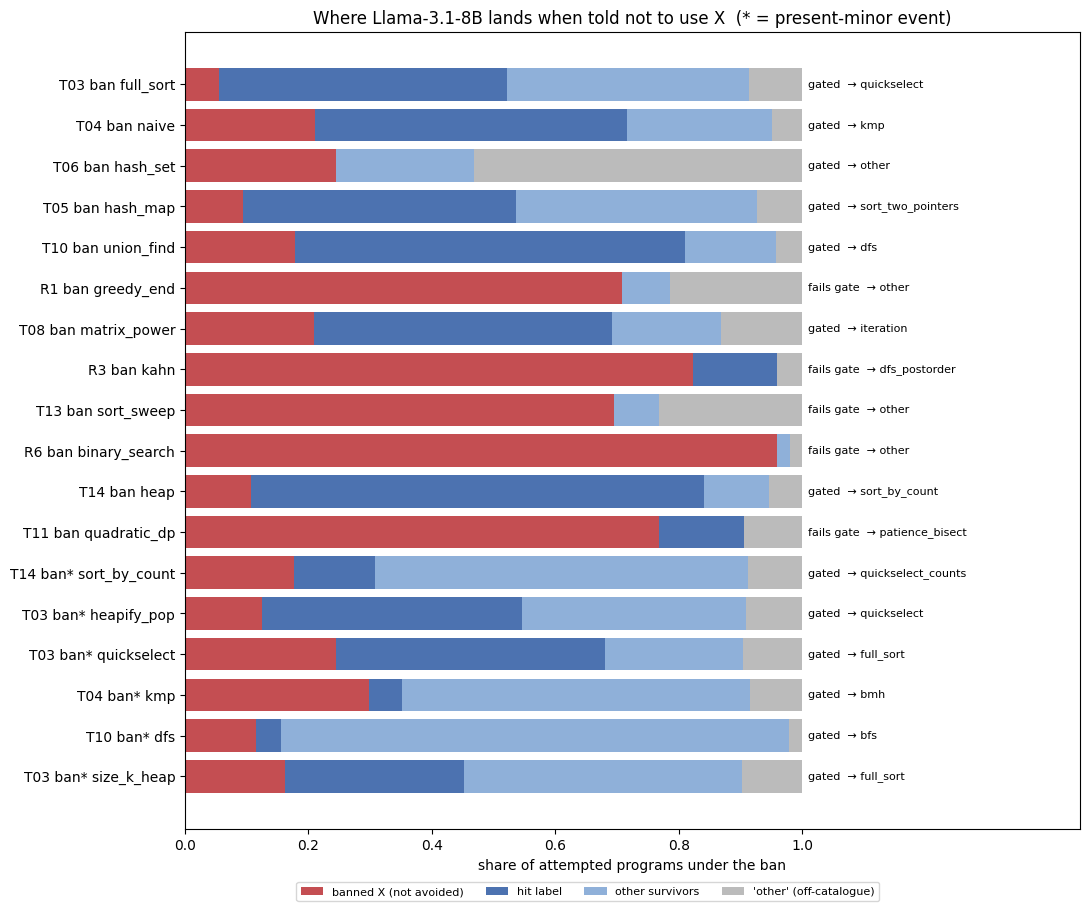

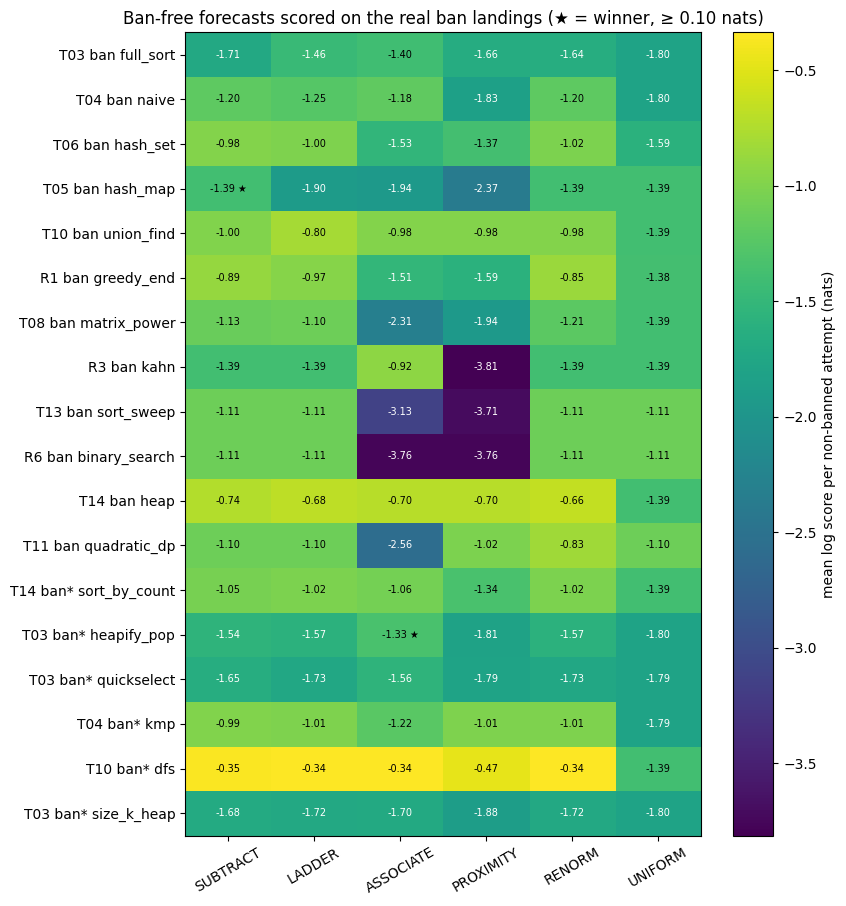

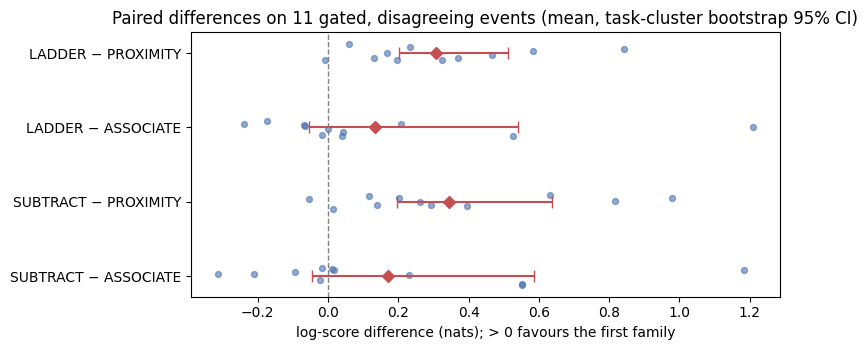

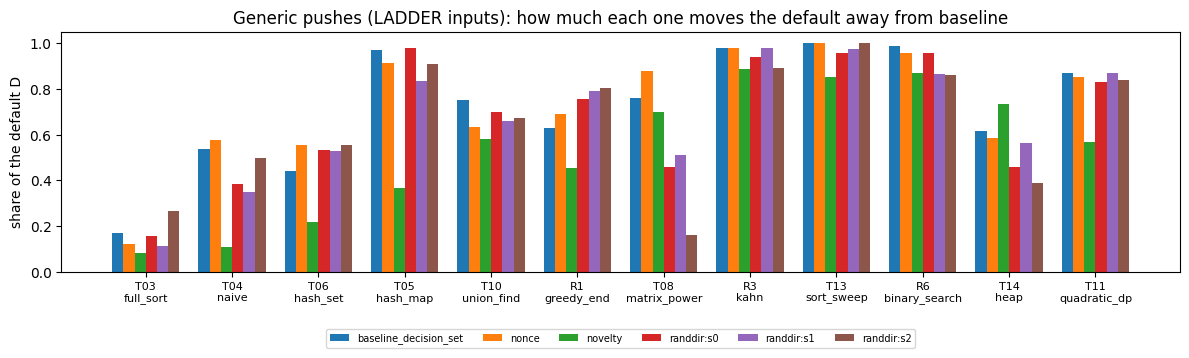

In [21]:
evs = list(res["events"])
labels_y = [short(e) for e in evs]

# ---- 1. landings
fig, ax = plt.subplots(figsize=(11, 0.42 * len(evs) + 1.6))
parts = {"banned X (not avoided)": [], "hit label": [], "other survivors": [], "'other' (off-catalogue)": []}
for e in evs:
    lc, X, h = res["events"][e]["table"]["landing_counts"], forecasts["events"][e]["X"], res["events"][e]["scored"]["hit_label"]
    n = sum(lc.values()) or 1
    nb, no = lc.get(X, 0), lc.get("other", 0)
    nh = lc.get(h, 0) if h not in (None, X, "other") else 0
    for k, v in zip(parts, (nb, nh, n - nb - nh - no, no)):
        parts[k].append(v / n)
left = np.zeros(len(evs))
for (k, v), col in zip(parts.items(), ("#c44e52", "#4c72b0", "#8fb0d9", "#bbbbbb")):
    ax.barh(labels_y, v, left=left, color=col, label=k)
    left += np.array(v)
for i, e in enumerate(evs):
    ax.text(1.01, i, ("gated" if res["events"][e]["table"]["gate_pass"] else "fails gate") + f"  → {res['events'][e]['scored']['hit_label']}",
            va="center", fontsize=8)
ax.invert_yaxis(); ax.set_xlim(0, 1.45); ax.set_xticks(np.linspace(0, 1, 6)); ax.set_xlabel("share of attempted programs under the ban")
ax.set_title("Where Llama-3.1-8B lands when told not to use X  (* = present-minor event)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.06), ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

# ---- 2. log-score heatmap
cols = FAMS + ["RENORM", "UNIFORM"]
M = np.array([[res["events"][e]["scored"]["logscore"][c] for c in cols] for e in evs], dtype=float)
fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(evs) + 1.6))
im = ax.imshow(M, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(cols)), cols, rotation=30); ax.set_yticks(range(len(evs)), labels_y)
for i, e in enumerate(evs):
    w = res["events"][e]["scored"]["winner"]
    for j, c in enumerate(cols):
        if not np.isnan(M[i, j]):
            ax.text(j, i, f"{M[i, j]:.2f}" + (" ★" if c == w else ""), ha="center", va="center", fontsize=7,
                    color="white" if M[i, j] < np.nanmean(M) else "black")
plt.colorbar(im, label="mean log score per non-banned attempt (nats)")
ax.set_title("Ban-free forecasts scored on the real ban landings (★ = winner, ≥ 0.10 nats)")
plt.tight_layout(); plt.show()

# ---- 3. paired differences (as src/figures.forest, with N_BOOT resamples)
rng = np.random.default_rng(0)
gd = [e for e in evs if res["events"][e]["scored"]["gate"]["gate_pass"] and res["events"][e]["scored"]["disagreeing"]]
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (a, b) in enumerate(PAIRS):
    d = [(res["events"][e]["scored"]["logscore"][a] - res["events"][e]["scored"]["logscore"][b], forecasts["events"][e]["task"]) for e in gd]
    if not d:
        continue
    vals = np.array([v for v, _ in d])
    ax.scatter(vals, np.full(len(vals), i) + rng.uniform(-0.12, 0.12, len(vals)), s=18, alpha=0.6, color="#4c72b0")
    tasks = sorted({t for _, t in d})
    boots = [np.mean([v for tk in rng.choice(tasks, size=len(tasks), replace=True) for v, t in d if t == tk]) for _ in range(N_BOOT)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    ax.errorbar(vals.mean(), i, xerr=[[vals.mean() - lo], [hi - vals.mean()]], fmt="D", color="#c44e52", capsize=4)
ax.axvline(0, color="grey", lw=1, ls="--")
ax.set_yticks(range(len(PAIRS)), [f"{a} − {b}" for a, b in PAIRS]); ax.set_xlabel("log-score difference (nats); > 0 favours the first family")
ax.set_title(f"Paired differences on {len(gd)} gated, disagreeing events (mean, task-cluster bootstrap 95% CI)")
plt.tight_layout(); plt.show()

# ---- 4. knob view
kv = res["knob_view"]
conds = ["baseline_decision_set", "nonce", "novelty", "randdir:s0", "randdir:s1", "randdir:s2"]
fig, ax = plt.subplots(figsize=(12, 3.8))
w = 0.13
for k, c in enumerate(conds):
    ax.bar(np.arange(len(FROZEN_TASKS)) + (k - 2.5) * w, [kv[t][c]["D_share"] for t in FROZEN_TASKS], w, label=c)
ax.set_xticks(range(len(FROZEN_TASKS)), [f"{t}\n{frozen['tasks'][t]['D']}" for t in FROZEN_TASKS], fontsize=8)
ax.set_ylabel("share of the default D"); ax.set_ylim(0, 1.05)
ax.set_title("Generic pushes (LADDER inputs): how much each one moves the default away from baseline")
ax.legend(fontsize=7, ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout(); plt.show()

### A ban the model ignores

Five defaults fail the gate: told not to, Llama still writes D. Below is one answer from R3 (topological order) under template W2. `mentions` checks whether the text names X in prose ("Kahn", "in-degree", ...). Identifiers do not count.

In [22]:
eid, rid = "R3|modal|kahn", "G1|R3|ban:kahn|2|7"
x = next(x for x in EXAMPLES if x["metadata_event_id"] == eid)
s = next(s for s in x["metadata_ban_samples"] if s["row_id"] == rid)
t, X = x["metadata_task"], x["metadata_banned"]
print(f"{eid}: the prompt said '{TEMPLATES[int(s['template'])].format(X=P.display(t, X))}'")
tab = res["events"].get(eid, {}).get("table")
if tab:  # (only when N_EVENTS includes R3)
    print(f"avoidance under the ban: {tab['avoidance']:.2f} (the gate needs 0.5); "
          f"{tab['disguise_rate']:.0%} of the programs that still use {X} never name it")
print(f"this sample: label = {s['label']}, passes the tests = {s['passed']}, names {X}: {X in mentions(t, s['text'])}\n")
print(s["text"])

R3|modal|kahn: the prompt said 'Your solution must not rely on Kahn's in-degree queue.'
avoidance under the ban: 0.18 (the gate needs 0.5); 63% of the programs that still use kahn never name it
this sample: label = kahn, passes the tests = True, names kahn: False

```python
def solve(n, prerequisites):
    edges = [[] for _ in range(n)]
    degrees = [0] * n
    for u, v in prerequisites:
        edges[v].append(u)
        degrees[u] += 1

    queue = [i for i in range(n) if degrees[i] == 0]
    res = []
    while queue:
        u = queue.pop(0)
        res.append(u)
        for v in edges[u]:
            degrees[v] -= 1
            if degrees[v] == 0:
                queue.append(v)

    return res if len(res) == n else []
```


## Takeaways

- **The CPU half of `method.py` reproduces from the frozen labels.** At the original parameters, the frozen defaults, the 18 events, every ban-free forecast, the per-event log scores and winners, and the C1 branch all equal the committed and reported values. With the reduced parameters of a quick run, the Monte Carlo p-values and bootstrap CIs differ slightly and the point results do not change.
- **NO FAMILY ADVANCES (aimed, unresolved).** Wins are rare: only 2 of the 11 gated, disagreeing events have a family ahead by ≥ 0.10 nats. SUBTRACT and LADDER beat PROXIMITY in the paired Wilcoxon tests, but none separates from ASSOCIATE. LADDER and ASSOCIATE hit the realised landing above chance (7/13 each). So where Llama goes under a ban is *predictable*, but no single mechanism (subtraction, generic push, association, code proximity) wins on log score.
- **Some defaults resist the ban itself.** R1, R3, T13, R6 and T11 fail the avoidance gate, so Llama keeps writing its default. The disguise rate shows how often those programs do so without even naming it.
- **The verdict is fragile.** The correct-only, bf16-only and drop-W4 sensitivities switch the branch to SUBSTITUTION (ASSOCIATE).